# Style Sheet

In [6]:
import matplotlib.pyplot as plt
import numpy as np
plt.style.use(r'style_sheets/base.mplstyle')

In [2]:
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from matplotlib.font_manager import FontProperties
 
 
# SI length ladder (value of each prefix in metres), low -> high
_SI_ORDER = [("pm", 1e-12), ("nm", 1e-9), ("µm", 1e-6),
             ("mm", 1e-3), ("cm", 1e-2), ("m", 1.0)]
_SI = dict(_SI_ORDER) | {"um": 1e-6}  # accept ASCII 'um' as an alias
 
 
def _nice_125(x):
    """Snap x>0 to the nearest {1,2,5}x10^n value, measured in log space."""
    if x <= 0:
        return x
    exp = np.floor(np.log10(x))
    mantissa = x / 10.0 ** exp                       # in [1, 10)
    candidates = np.array([1.0, 2.0, 5.0, 10.0])     # 10 catches top of decade
    m = candidates[np.argmin(np.abs(np.log(candidates) - np.log(mantissa)))]
    return m * 10.0 ** exp
 
 
def _format_length(value, units, scale=True):
    """Relabel a length with the most readable SI prefix (physical size fixed)."""
    if not scale or units not in _SI:
        return f"{value:g} {units}"
    metres = value * _SI[units]
    name, fac = _SI_ORDER[0]
    for n, f in _SI_ORDER:                            # largest prefix with mantissa >= 1
        if metres >= f:
            name, fac = n, f
    return f"{metres / fac:g} {name}"
 
 
def add_scalebar(ax, dx, units="nm", length_fraction=0.1,
                 loc="lower right", color="black", box_alpha=0.0,
                 height_fraction=0.01, sep=4, pad=0.4,
                 fontsize=None, label_top=False, scale_units=True):
    """
    Add a physical scale bar to `ax`.
 
    Parameters
    ----------
    ax : matplotlib.axes.Axes
    dx : float
        Physical size of one data unit (e.g. nm per pixel).
    units : str
        Units of `dx`. Length units (pm, nm, µm/um, mm, cm, m) auto-rescale
        for the label when `scale_units` is True.
    length_fraction : float
        Target fraction f of the x-axis the bar should span; the drawn length
        is the {1,2,5}x10^n value closest (in log) to f * W * dx.
    loc : str or int
        Anchor location, e.g. 'lower right'.
    color : str
        Bar and text colour ('white' is usual on dark micrographs).
    box_alpha : float
        Background box opacity; 0 -> no frame.
    height_fraction : float
        Bar thickness as a fraction of the y-axis range.
    sep : float
        Gap (pt) between bar and label.
    pad : float
        Padding (in fontsize units) inside the anchored box.
    fontsize : float or None
    label_top : bool
        Put the label above the bar instead of below.
    scale_units : bool
        Auto-pick a readable SI prefix for the label.
 
    Returns
    -------
    AnchoredSizeBar
    """
    # axis extent in data units
    x0, x1 = ax.get_xlim()
    W = abs(x1 - x0)
 
    # target physical length -> nice value -> length back in data units
    nice = _nice_125(length_fraction * W * dx)
    size_data = nice / dx
 
    # bar thickness in data units
    y0, y1 = ax.get_ylim()
    size_vertical = height_fraction * abs(y1 - y0)
 
    label = _format_length(nice, units, scale=scale_units)
    fontprops = FontProperties(size=fontsize) if fontsize is not None else None
 
    bar = AnchoredSizeBar(
        ax.transData,
        size_data,
        label,
        loc=loc,
        pad=pad,
        sep=sep,
        color=color,
        frameon=(box_alpha > 0),
        size_vertical=size_vertical,
        label_top=label_top,
        fontproperties=fontprops,
    )
    if box_alpha > 0:                                # match box_alpha semantics
        bar.patch.set_alpha(box_alpha)
        bar.patch.set_facecolor("white")
        bar.patch.set_edgecolor("none")
 
    ax.add_artist(bar)
    return bar


In [3]:
from pathlib import Path

def save_fig(fig=None, path="figure", *, dpi=600, transparent=True,
             pad_inches=0.05, editable_text=False, also=None):
    """Save a Matplotlib figure as a publication-ready SVG.

    Parameters
    ----------
    fig : Figure, optional
        Figure to save. Defaults to the current figure (plt.gcf()).
    path : str or Path
        Output path. A '.svg' suffix is added if missing.
    dpi : int
        Resolution of *embedded raster layers only* (e.g. imshow images);
        vector elements are unaffected. 600 keeps micrographs crisp.
    transparent : bool
        Transparent figure/axes background (lets the SVG sit on any page color).
    pad_inches : float
        Padding around the tight bounding box, in inches.
    editable_text : bool
        If True, keep glyphs as <text> (editable in Illustrator/Inkscape,
        smaller files). Ignored when text.usetex=True, since LaTeX emits paths.
    also : str or list of str, optional
        Extra formats to write alongside the SVG, e.g. 'pdf' or ['pdf', 'png'].
    """
    fig = fig or plt.gcf()
    path = Path(path).with_suffix(".svg")
    path.parent.mkdir(parents=True, exist_ok=True)

    if editable_text and not plt.rcParams.get("text.usetex", False):
        plt.rcParams["svg.fonttype"] = "none"

    kw = dict(dpi=dpi, transparent=transparent,
              bbox_inches="tight", pad_inches=pad_inches)

    fig.savefig(path, **kw)

    if also:
        for fmt in ([also] if isinstance(also, str) else also):
            fig.savefig(path.with_suffix(f".{fmt}"), **kw)

    return path

# Introduction Figures

In [4]:
 ['#0072B2', '#009E73', '#E69F00', '#D55E00', '#CC79A7', '#484848', '#9C9C9C']

['#0072B2', '#009E73', '#E69F00', '#D55E00', '#CC79A7', '#484848', '#9C9C9C']

# Newton Rings Equation

WindowsPath('Figures/NewtonRings.svg')

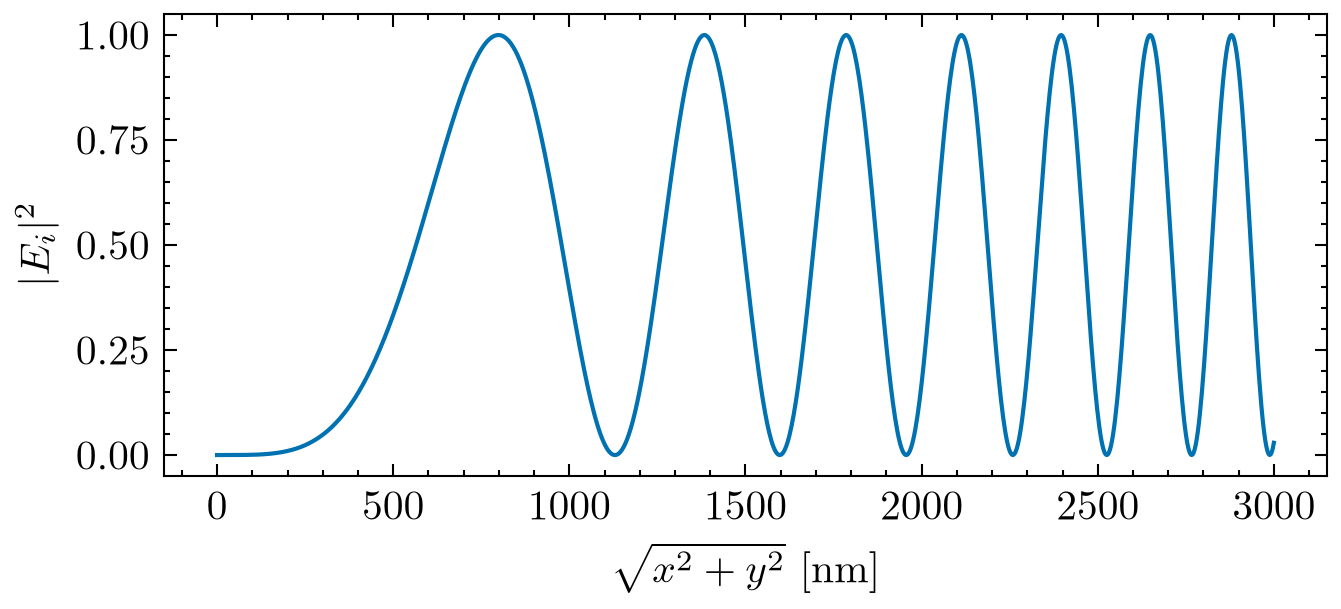

In [74]:
fig = plt.figure(figsize=(5,2))
ax = fig.add_subplot(111)

x_range = np.linspace(0, 3000, 1000) # each step is a nm

def NewtonRing(x, R_c, w):

    coef = x**2 * 2 * np.pi / (2 * R_c *w)
    return 1-(np.cos(coef))**2

ax.plot(x_range, NewtonRing(x_range, 45 * 10*(7), 405))
ax.set_ylabel(r'$|E_i|^2$')
ax.set_xlabel(r'$\sqrt{x^2 + y^2}$ [nm]')

save_fig(fig, r'Figures/NewtonRings.svg')


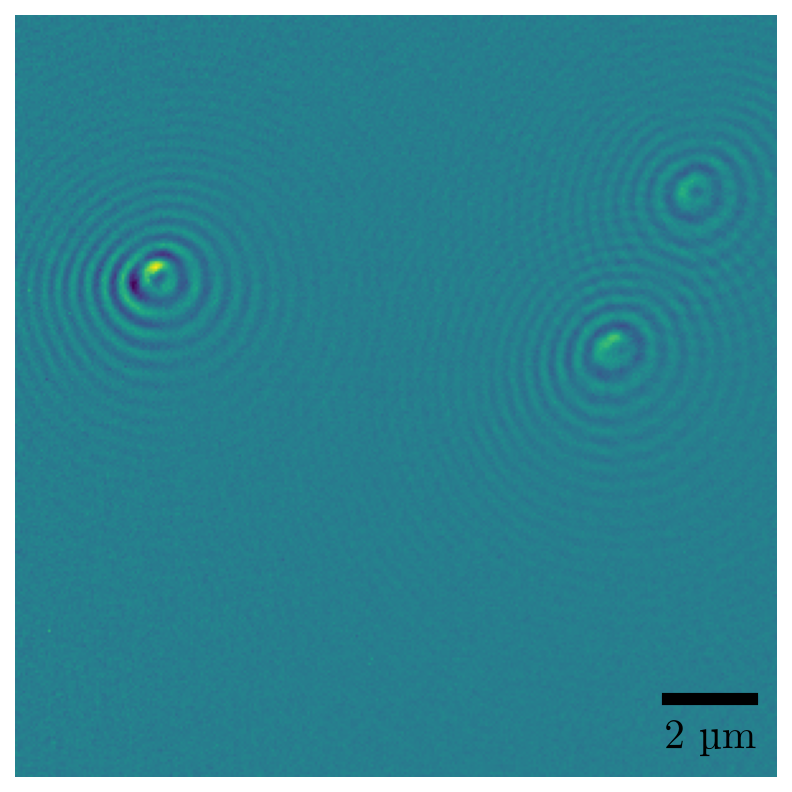

In [8]:
%matplotlib inline
import mat73 
from matplotlib_scalebar.scalebar import ScaleBar

stuff = mat73.loadmat('normalization_pipeline.mat')
stuff.keys()

a = stuff['aa4']
b = stuff['frame_16']
c = stuff['im']
d = stuff['im1']
e = stuff['mean_bg']


fig = plt.figure()
ax = fig.add_subplot(111)

ax.imshow(c[100:400, 100:400])
# # Create scale bar
add_scalebar(ax, 55, 'nm', 0.1)
ax.set_axis_off()

#save_fig(fig, r'Figures/still.svg')

# normalization


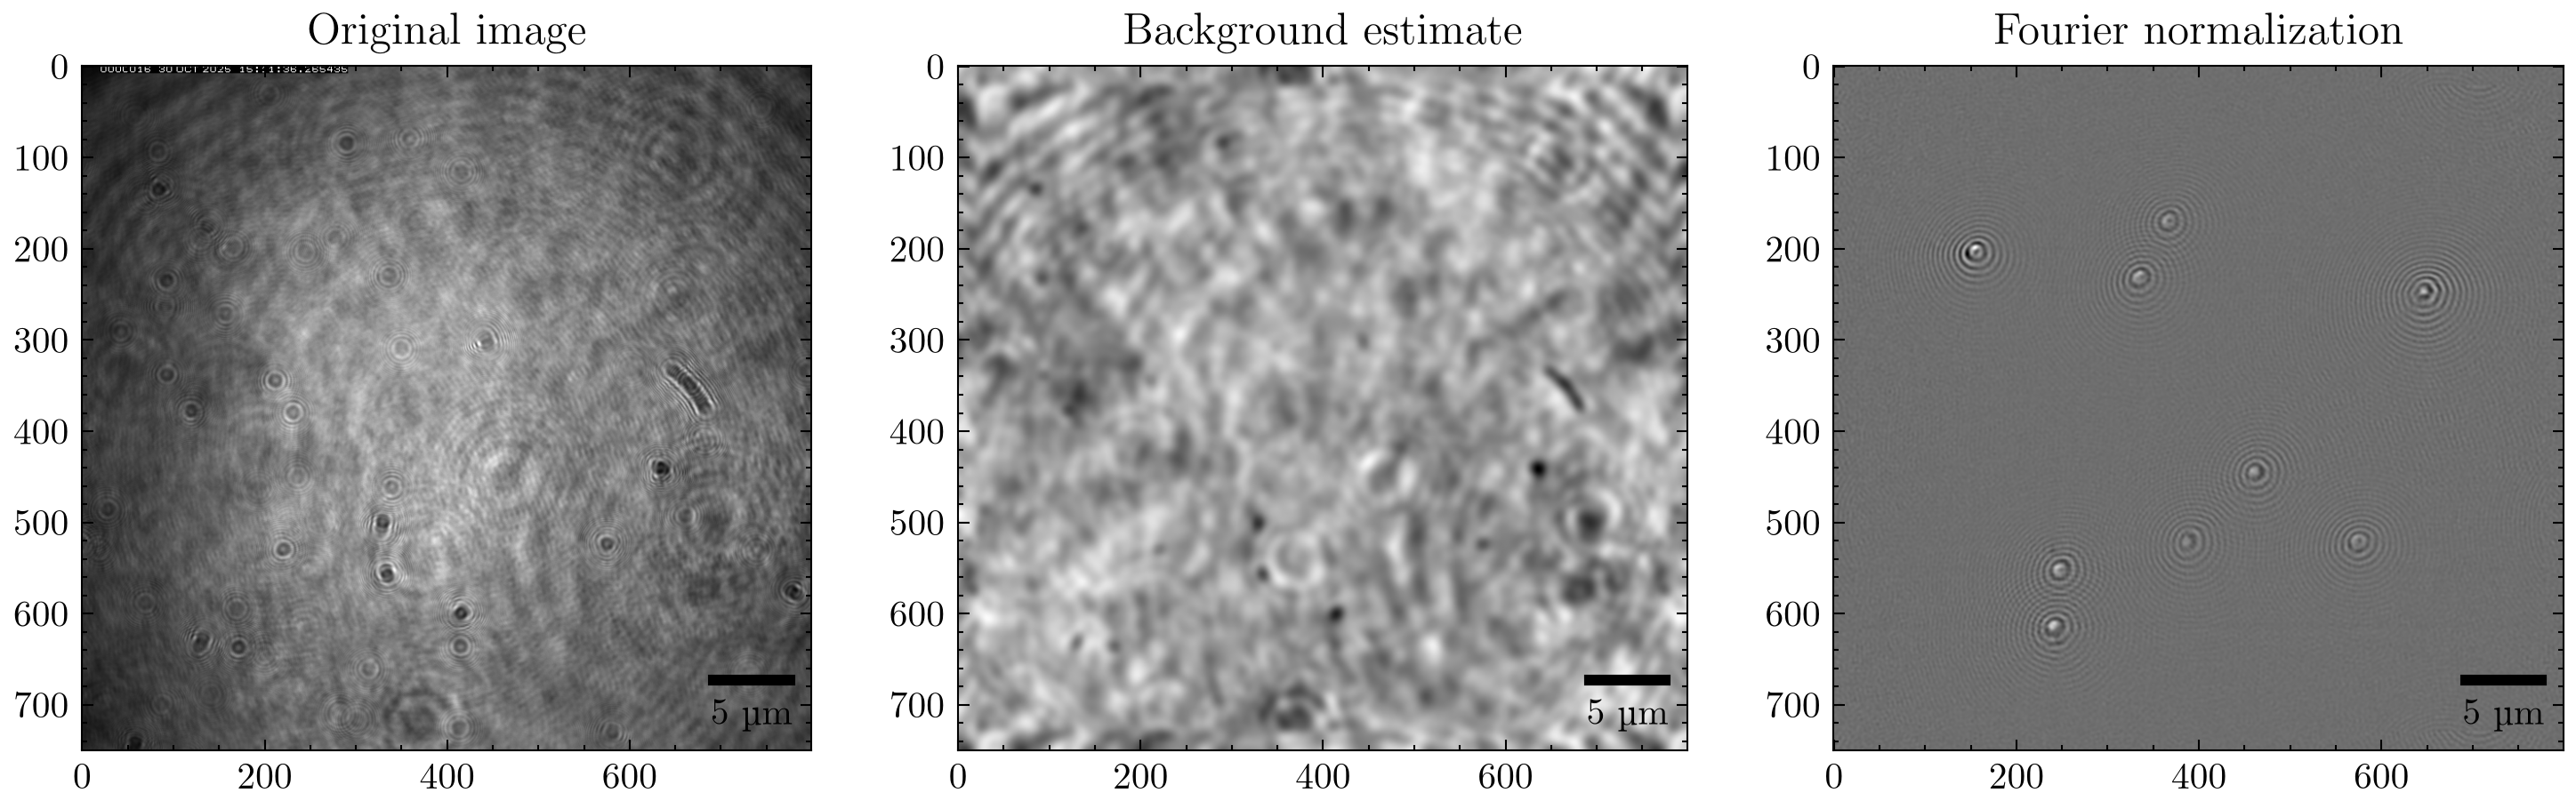

PosixPath('Figures/NormalizationPipeline.svg')

In [14]:

fig = plt.figure(figsize=(12,6), dpi=300)

ax1 = fig.add_subplot(131)
ax2 = fig.add_subplot(132)
ax3 = fig.add_subplot(133)


# images
ax1.imshow(b, cmap='gray')
ax2.imshow(e, cmap='gray')
ax3.imshow(a, cmap='gray')
add_scalebar(ax1, 55, 'nm', 0.1)
add_scalebar(ax2, 55, 'nm', 0.1)
add_scalebar(ax3, 55, 'nm', 0.1)





# panel titles
ax1.set_title("Original image")
ax2.set_title("Background estimate")
ax3.set_title("Fourier normalization")


plt.show()
save_fig(fig, 'Figures/NormalizationPipeline', also=['pdf', 'png'])


# stuff



In [ ]:
# importz
import numpy as np
import h5py
import os
from tqdm import tqdm
import matplotlib.pyplot as plt

class SingleParticle():
    def __init__(self, x,y,z):
        self.traj_x = x
        self.traj_y = y
        self.traj_z = z

def LoadDataset(file_name):
    '''
    Loads the h5 dataset developed by martin's TracesROi_to_z_analysis.py script.
    '''
    dataset_all = []
    # Open the file in read mode
    with h5py.File(file_name, 'r') as f:
        #print(f"Keys in the HDF5 file: {list(f.keys())}")
        
        # Iterate through keys and print their types
        for key in f.keys():
            #print(f"Object name: {key}, Object type: {type(f[key])}")
            dset = f[key] # this is a croup with N_particles which are all 'members'
            for particle_index in dset:
                #print(dset[particle_index].keys())

                # this reads in a pointer
                grp = dset[particle_index]
                # This accesses the memory directly
                curr_particle = SingleParticle(
                    grp['x'][:],
                    grp['y'][:],
                    grp['z'][:],
                    #grp['diffusion_msd'][()],
                    #grp['diffusion_confined'][()],
                    #grp['length_confined'][()]
                )
                # append the data to the dataset file
                dataset_all.append(curr_particle)

    print(f'Particles in Current Dataset: {len(dataset_all)}')
    return dataset_all



# List of Datasets For Figure 1
# Polystyrene + PBS
#path_to_folder = r'Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_75p\ClicOnLeft4'

# get all the ROI Traces paths
path_to_files = [r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_75p\ClicOnLeft2\Test_iSCAT_2026-06-16_2_22_06_PM_350_500.mat"]
# --------------------------------------------------------------------
# LOOP STARTS HERE
# --------------------------------------------------------------------
for current_path in tqdm(path_to_files, desc='File Loading Bar', ascii=True, ):
    # These all need to be mat files
    suffix = current_path.split('.')[-1]
    if suffix == 'mat':
        print('Current Path analyzed; {}'.format(current_path))
    else:
        print('Current Path is not mat; {} \n Skipping...'.format(current_path))
        continue

    # ---------------------------------------------------
    # File Processing
    # ---------------------------------------------------
    current_title = current_path.split('\\')[-1]
    mat_arr = None

    try:
        from scipy.io import loadmat
        mat_arr = loadmat(current_path)
    except Exception as e:
        print('scipy didnt work')

    if mat_arr == None:
        try:
            print('trying mat')
            from mat73 import loadmat
            mat_arr = loadmat(current_path)
            print('mat loaded')
            
        except Exception as e:
            print('mat73 didnt work')

    # at this point, we should have ROI_Traces loaded in (huge file)
    ROI_traces = mat_arr['Traces_ROI']  # H, W , F
    Traces = mat_arr['Traces']

    # obtain active only
    ACTIVE_ROI = ROI_traces[0]
    ACTIVE_Traces = Traces[0]

    # There are going to be multiple particles in each of these files
    # lets store them all into this container, then loop over them
    CONTAINER_ROI = []  # list where each element is roi_info (F, P, P)
    CONTAINER_Traces = []

    # loop over active ROI an extract ROI per PID
    for item_roi, item_trace in zip(ACTIVE_ROI[0], ACTIVE_Traces[0]):
        # shape requirements
        if np.ndim(item_roi) != 2 or np.ndim(item_trace) != 2:
            print('Particle has shape error')
            continue
        # print(np.shape(item_roi))
        # print(np.shape(item_trace))
        item_roi = np.asarray(item_roi)
        item_trace = np.asarray(item_trace)
        # Handle both possible shapes robustly:
        if item_roi.ndim == 2:
            N, P = item_roi.shape
            F = N // P
            roi_info = item_roi.reshape(F, P, P)
        else:
            print(f"Unexpected element.ndim = {item_roi.ndim}")
            continue

        curr_ndim = np.ndim(item_trace)
        if curr_ndim == 2:
            curr_frame = item_trace[:, 0]
            curr_x = item_trace[:, 1]
            curr_y = item_trace[:, 2]
            tupled_information = (curr_frame, curr_x, curr_y)
            CONTAINER_Traces.append(tupled_information)
            CONTAINER_ROI.append(roi_info)
        else:
            continue

        # This contains all the information for every traces particle up until the Axial Measurement Part
        length_traces = len(CONTAINER_Traces)
        length_ROI = len(CONTAINER_ROI)

        try:
            if length_traces == length_ROI:  # These need to match
                CONTAINER_Particles = (CONTAINER_Traces, CONTAINER_ROI)
            elif length_traces < length_ROI:
                CONTAINER_Particles = (CONTAINER_Traces, CONTAINER_ROI[:length_traces])
            elif length_traces > length_ROI:
                CONTAINER_Particles = (CONTAINER_Traces[:length_ROI], CONTAINER_ROI)
        except Exception as e:
            print('Traces and ROI have different number of particles')
            CONTAINER_Particles = (0, 0)

    print('Trace information is loaded in')

# sample ROI TRACES 
PS_PBS0p01_225nm_ROI = CONTAINER_Particles



#PS_PBS0p1_225nm   = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_75p\ClicOnLeft2\Test_iSCAT_2026-06-16_2_22_06_PM_350_500.mat")
# PS_PBS0p01_225nm  = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p01\center2\center2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
# PS_PBS0p001_225nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_2\center_2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
# #PS_PBS0p001_300nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_3\center_3radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
# #PS_PBS0p001_375nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_4\center_4radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
# PS_PBS0p00001_225nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p00001\ClicOnLeft_2\ClicOnLeft_2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")

particle_test = PS_PBS0p01_225nm_ROI
roi = PS_PBS0p01_225nm_ROI[1][0]
trace = PS_PBS0p01_225nm_ROI[0][0]

# custom function
from hdr.axial_estimation import *              # Axial Diffusion Estimation
from hdr.transverse_estimation import *         # Transverse Diffusion Estimation
# h5 handling
from hdr.h5_tools import *
from hdr.recenter_roi import *

m_2MAX = 240
m_3MAX = 240 + 75
m_4MAX = 240 + 75 + 75

# --------------------------------------------------------------------
# Constants
# --------------------------------------------------------------------
microscope_setting = {'fps': 585, #400
                      'px_size': 55 * 10**(-9)}

recenter_settings = {'sym_width': 3,
                     'rmin': 8,
                     'rmax': 25}

radial_settings = {'fixed_r': 39,
                   'rad_int_theta': 359,
                   'theta_naught': 50,
                   'random_angle': False,
                   'weight_start': 8,
                   'weight_end': 26}


max_STEP = 5       # nm gly = 20, no gly = 80
curr_MAX = m_2MAX

# Now, we need to do the data extraction per particle
exposure_time = 1/microscope_setting['fps']
pixel_size_m = microscope_setting['px_size']
pixel_size_nm = pixel_size_m * 10**9

from scipy.constants import Boltzmann as kb

try:
    # -----------------------------------------
    # Phase 0 - XY Diffusion Inference
    # -----------------------------------------

    print(f"Starting Particle: {0}", end='\n')

    # Transverse Parameters
    x_traj = trace[1] #* pixel_size_m
    y_traj = trace[2] #* pixel_size_m
    video_length_transverse = len(x_traj)
    print("Particle Trace is registered... ", end='')
    
    # omit short tracks
    if video_length_transverse < 300:
        print('Particle Track too short, skipping...')

    print("Starting Diffusion Calculation...", end='\n')
    
    trajectory = (x_traj, y_traj)
    
    x_traj_return = trace[1] * pixel_size_m #nm
    y_traj_return = trace[2] * pixel_size_m #nm


    # -----------------------------------------
    # Phase 1 - z position Inference
    # -----------------------------------------

    print("Axial Tracking Starting...", end='\n')
    # Axial Estimation Function
    try:
        # recenter roi
        roi_shift = []
        F, H, W = np.shape(roi)
        mask = np.zeros((H, W))
        for i in range(H):
            for j in range(W):
                rad = np.sqrt((H/2-i)**2 + (W/2-j)**2)
                if rad <= 30:
                    mask[i ,j] = 1
                else:
                    mask[i,j] = 0
        for index,frame in enumerate(roi):
            try:
                (shift_x, shift_y) = recenterDisplacement(frame,
                                                        mask,
                                                        recenter_settings['sym_width'],
                                                        recenter_settings['rmin'],
                                                        recenter_settings['rmax']
                                                        )
            except:
                print(index)
                
            shifted_roi = shift(frame, (shift_y, shift_x), mode='grid-wrap')
            roi_shift.append(shifted_roi)

        try:
            fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,6))
            ax1.imshow(roi_shift[0])
            #ax1.imshow(mask, alpha=0.5)
            ax2.imshow(roi[0])
            ax1.plot(H/2, W/2, 'ro')
            ax2.plot(H/2, W/2, 'ro')
            plt.show(block=False)
            time.sleep(1)
        except Exception as e:
            print(e)

        # recast to an np array
        roi_shift = np.array(roi_shift)

        # define weight
        w_r = np.zeros((radial_settings['fixed_r'] + 1,)) # size is int(fixed_r + 1) or (0, fixed_r) lol
        #w_r[8:26] = 1
        ws = radial_settings['weight_start']
        we = radial_settings['weight_end']
        w_r[ws:we] = 1
        # axial tracking

        opt = getAxialInference(roi                 = roi_shift,
                                k                   = 2 * np.pi / (405.0 / 1.33),
                                pixel_size_nm       = microscope_setting['px_size'] * 10**9,
                                fixed_r             = radial_settings['fixed_r'],
                                rad_int_theta       = radial_settings['rad_int_theta'],
                                theta_naught        = radial_settings['theta_naught'],
                                random_angle        = radial_settings['random_angle'],
                                bounds0             =[(1, 3000), (0.01, 2), (1, 5000)],
                                z_grid_revisions    = 2,
                                channel_length0_nm  = curr_MAX,
                                chain_linker_cost   = max_STEP,   # max horizontal step in nm
                                linker_weight       = (1.0, 0), # all weighting for steps is on dx)
                                w_r                 = w_r,
                                we                  = we,
                                ws                  = ws,
                                plot_3_param = True,
                                plot_2_param = False,
                                debug = True,
                                )
        print("Axial Diffusion Success...", end='\n')

    except Exception as e:
        print("Axial Diffusion Failure...", end='\n')
        print('Exception ', e)

except Exception as e:
        print("Axial Diffusion Failure...", end='\n')
        print('Exception ', e)


z_traj = opt['z']
r_arr = opt['r_arr']
rad_av_arr = opt['rad_av_arr']
roi_dss = opt['roi']
marr = opt['mask_arr']

File Loading Bar:   0%|          | 0/1 [00:00<?, ?it/s]

Current Path analyzed; Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_75p\ClicOnLeft2\Test_iSCAT_2026-06-16_2_22_06_PM_350_500.mat
scipy didnt work
trying mat


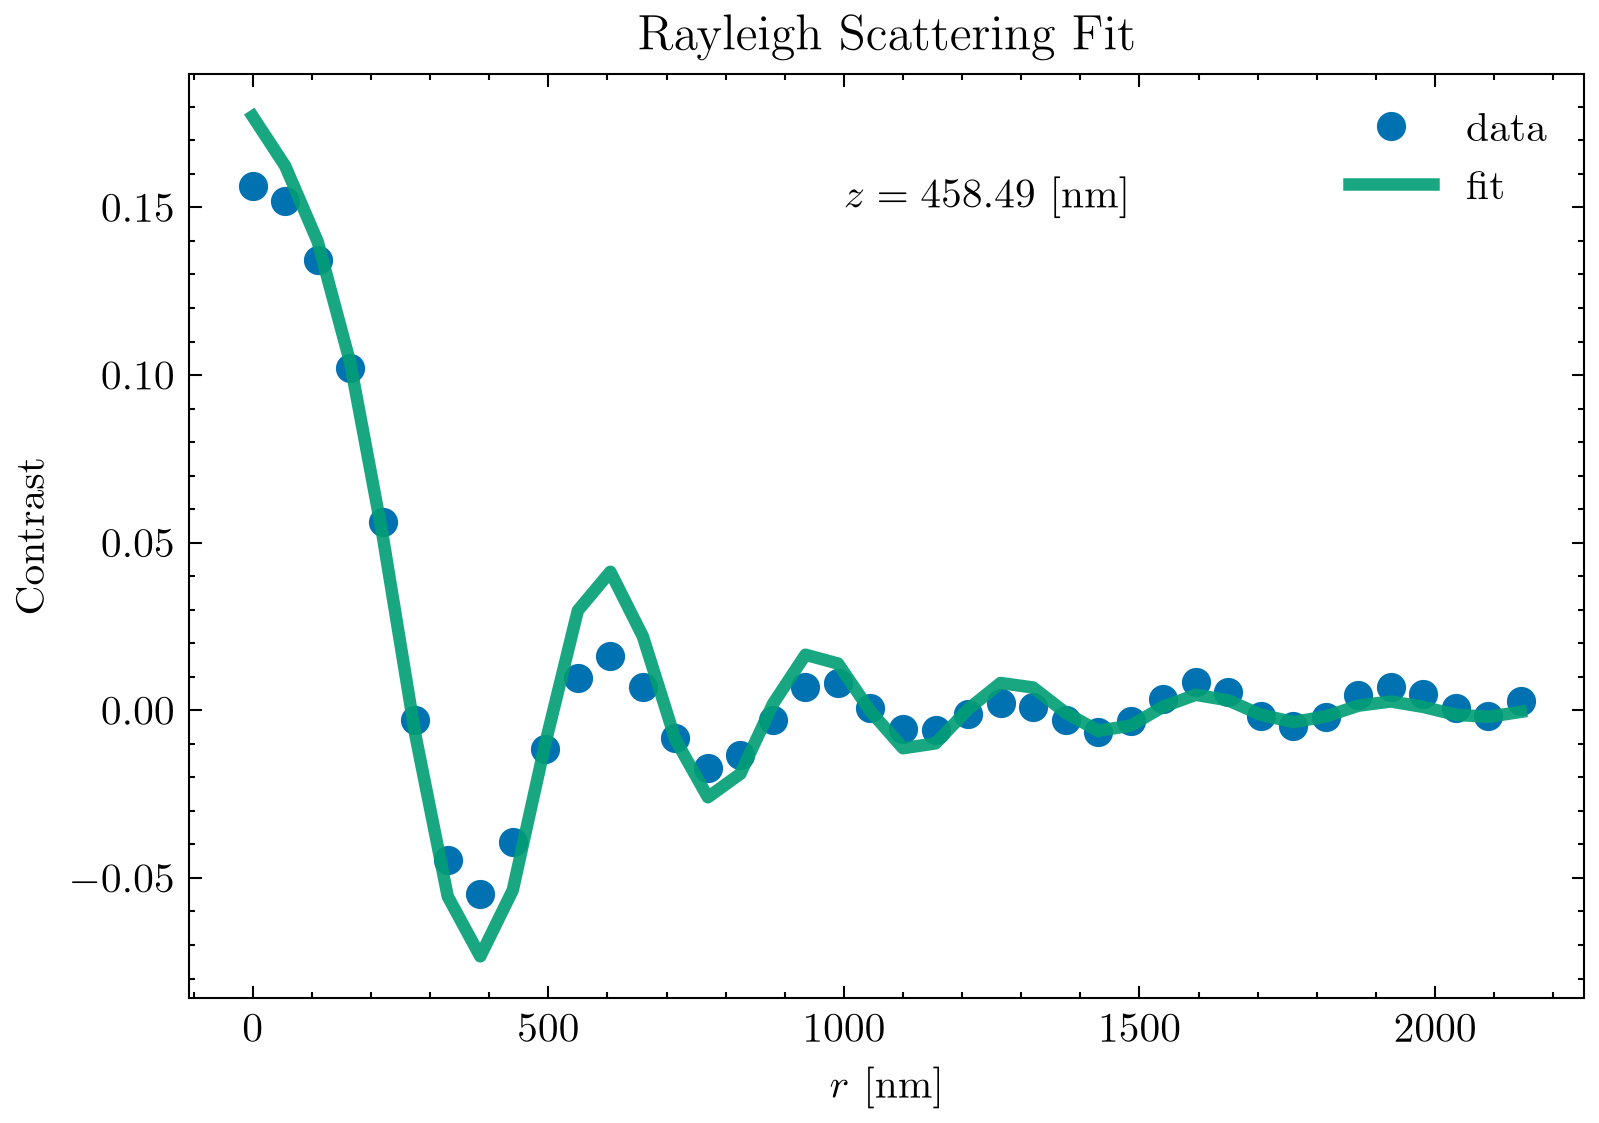

In [ ]:
fit = iPSF_radial(r_arr, 2 * np.pi / (405.0 / 1.33), z_traj[0], opt['E0'], 0,   opt['ef']) 

# plt.imshow(roi_dss[0])
# plt.imshow(marr[0], alpha=0.5)
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(r_arr, rad_av_arr[0], label='data', marker='o', linestyle ='None')
ax.plot(r_arr, fit, label='fit', linewidth=3, alpha=0.9)
ax.legend()
ax.set_ylabel('Contrast')
ax.set_xlabel(r'$r$ [nm]')
ax.set_title('Rayleigh Scattering Fit')

ax.text(1000, 0.15, f'$z = {z_traj[0]:.2f}$ [nm]')
save_fig(fig, r'Figures/Rayleigh Fit.svg')
plt.show()

WindowsPath('trajectory.svg')

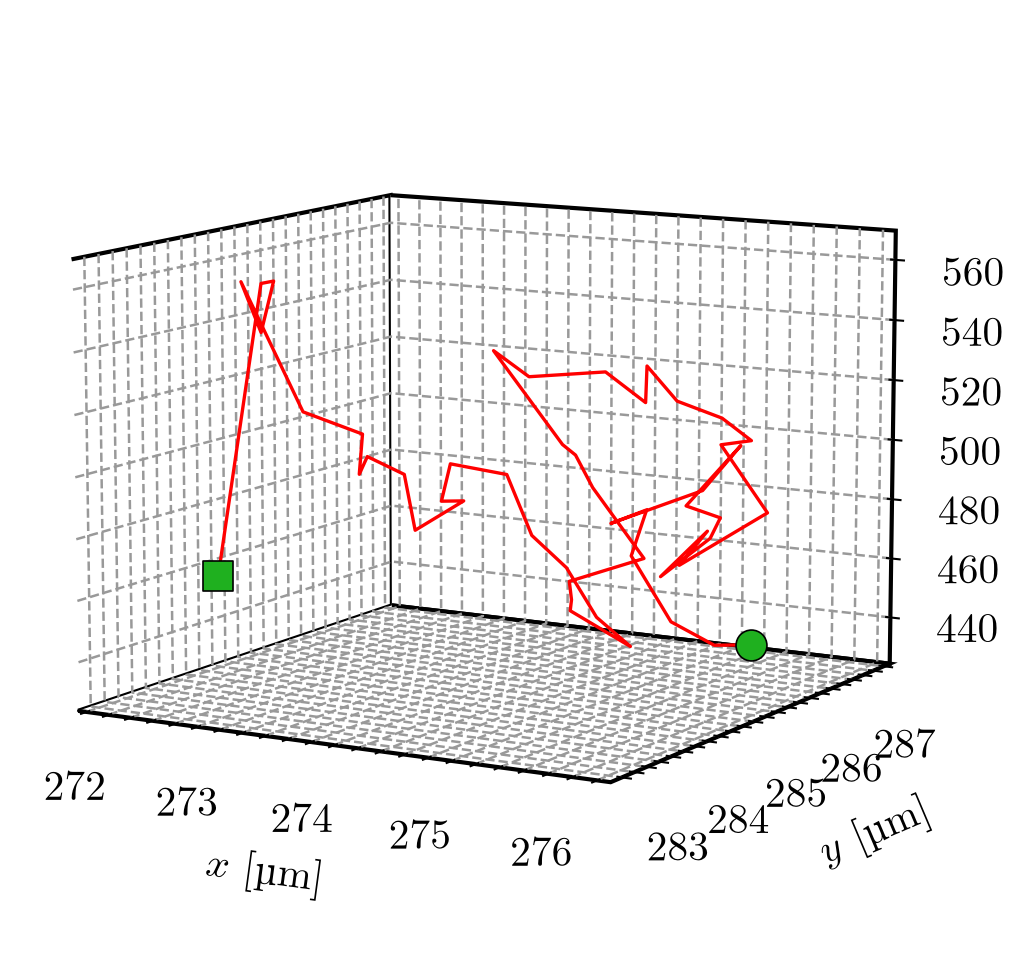

In [ ]:
x_traj = trace[1]
y_traj = trace[2]
z_traj = z_traj

fig = plt.figure(figsize=(4, 5))
ax = fig.add_subplot(projection='3d')
 
f2u = 50
# trajectory as a thin continuous red line (no markers)
ax.plot(x_traj[:f2u], y_traj[:f2u], z_traj[:f2u], color='red', lw=0.8)
 
# endpoints: square at the start r(t_0), circle at the end r(t_N)
GREEN = '#1fb01f'
ax.scatter(x_traj[0], y_traj[0], z_traj[0],
           marker='s', s=55, color=GREEN, edgecolor='k', lw=0.4, zorder=5)
ax.scatter(x_traj[f2u-1], y_traj[f2u-1], z_traj[f2u-1],
           marker='o', s=55, color=GREEN, edgecolor='k', lw=0.4, zorder=5)
 
# axis labels in µm
ax.set_xlabel(r'$x$ [µm]')
ax.set_ylabel(r'$y$ [µm]')
ax.set_zlabel(r'$z$ [µm]')
 
# panel tag in axes-fraction coordinates
#ax.text2D(0.03, 0.90, '(e)', transform=ax.transAxes,         fontsize=14, fontweight='bold')
 
# white panes with dashed grey gridlines
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_pane_color((1, 1, 1, 1))     # white walls
    axis.pane.set_edgecolor('k')          # black box edges
    axis._axinfo['grid'].update(color='0.6', linestyle='--', linewidth=0.6)
 
# low-elevation 3D box: x recedes front-left, y front-right
ax.view_init(elev=10, azim=-60)
 
save_fig(fig, 'trajectory.svg')
#plt.show()
 


WindowsPath('Figures/xy.svg')

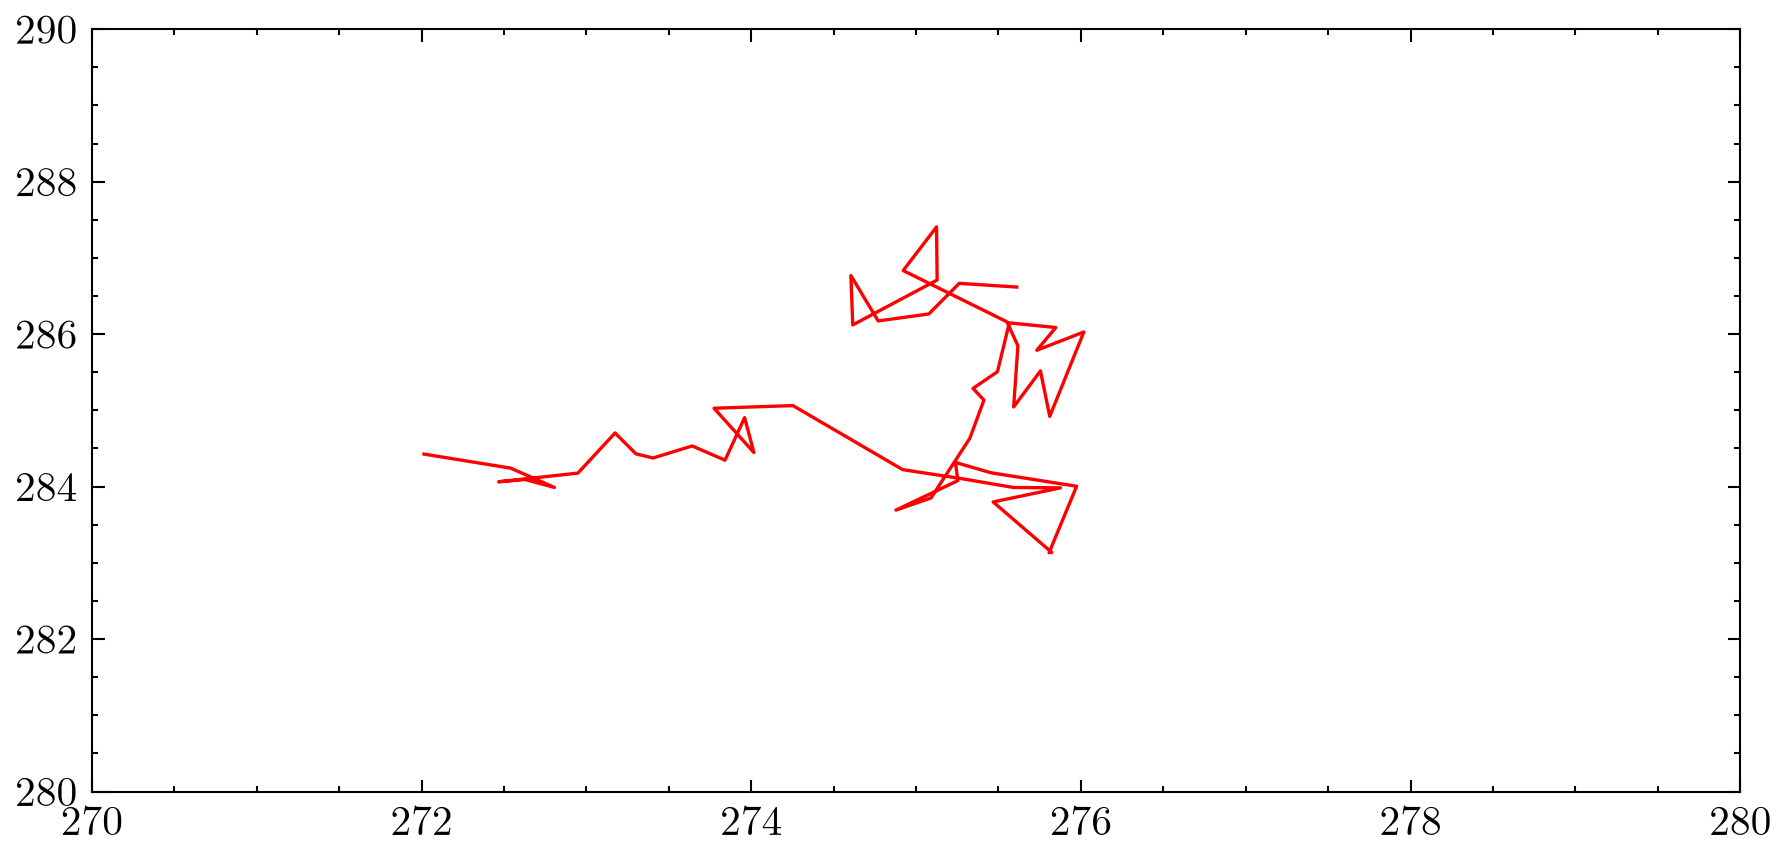

In [ ]:
fig = plt.figure()
plt.xlim(270, 280)
plt.ylim(280, 290)
plt.plot(x_traj[:f2u], y_traj[:f2u], color='red', lw=0.8)
save_fig(fig, r'Figures/xy.svg')

In [ ]:
PS_PBS1_GLY45p_225nm   = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_1_GLY_75p\ClicOnLeft2\ClicOnLeft2radial_int_50_to_359ws_8_we_26maxstep5nm_PythonAnalysis.h5")
panel_a_datasets = [PS_PBS1_GLY45p_225nm]#, PS_PBS1_GLY45p_300nm]

# loop over each dataset
x_trajectories = []
y_trajectories = []
z_trajectories = []

for dataset in panel_a_datasets:
    temp = []
    #bins = []
    # loop over all particles in the set
    for PID in dataset:
        x_trajectories.append(np.array(PID.traj_x))
        y_trajectories.append(np.array(PID.traj_y))
        z_trajectories.append(np.array(PID.traj_z))
        

print(f'{len(x_trajectories)} particles loaded.')

from hdr.transverse_estimation import getMeanSquaredDisplacement

def GetStuffFast(index):
    # assemble trajectory vectors
    xy_traj = np.array([x_trajectories[index], y_trajectories[index]]) * 1/(10**(-9))         # nm
    z_traj =  np.reshape(np.array([z_trajectories[index]]), (1, len(z_trajectories[index])))  # nm

    return xy_traj, z_traj

index = 0
# assemble trajectory vectors
xy_traj = np.array([x_trajectories[index], y_trajectories[index]]) * 1/(10**(-9))         # nm
z_traj =  np.reshape(np.array([z_trajectories[index]]), (1, len(z_trajectories[index])))  # nm

# Calculate the MSD

t_MSD, t_lag, t_ndim = getMeanSquaredDisplacement(xy_traj) 
z_MSD, z_lag, z_ndim = getMeanSquaredDisplacement(z_traj)

Particles in Current Dataset: 7
7 particles loaded.


WindowsPath('Figures/xy_MSD.svg')

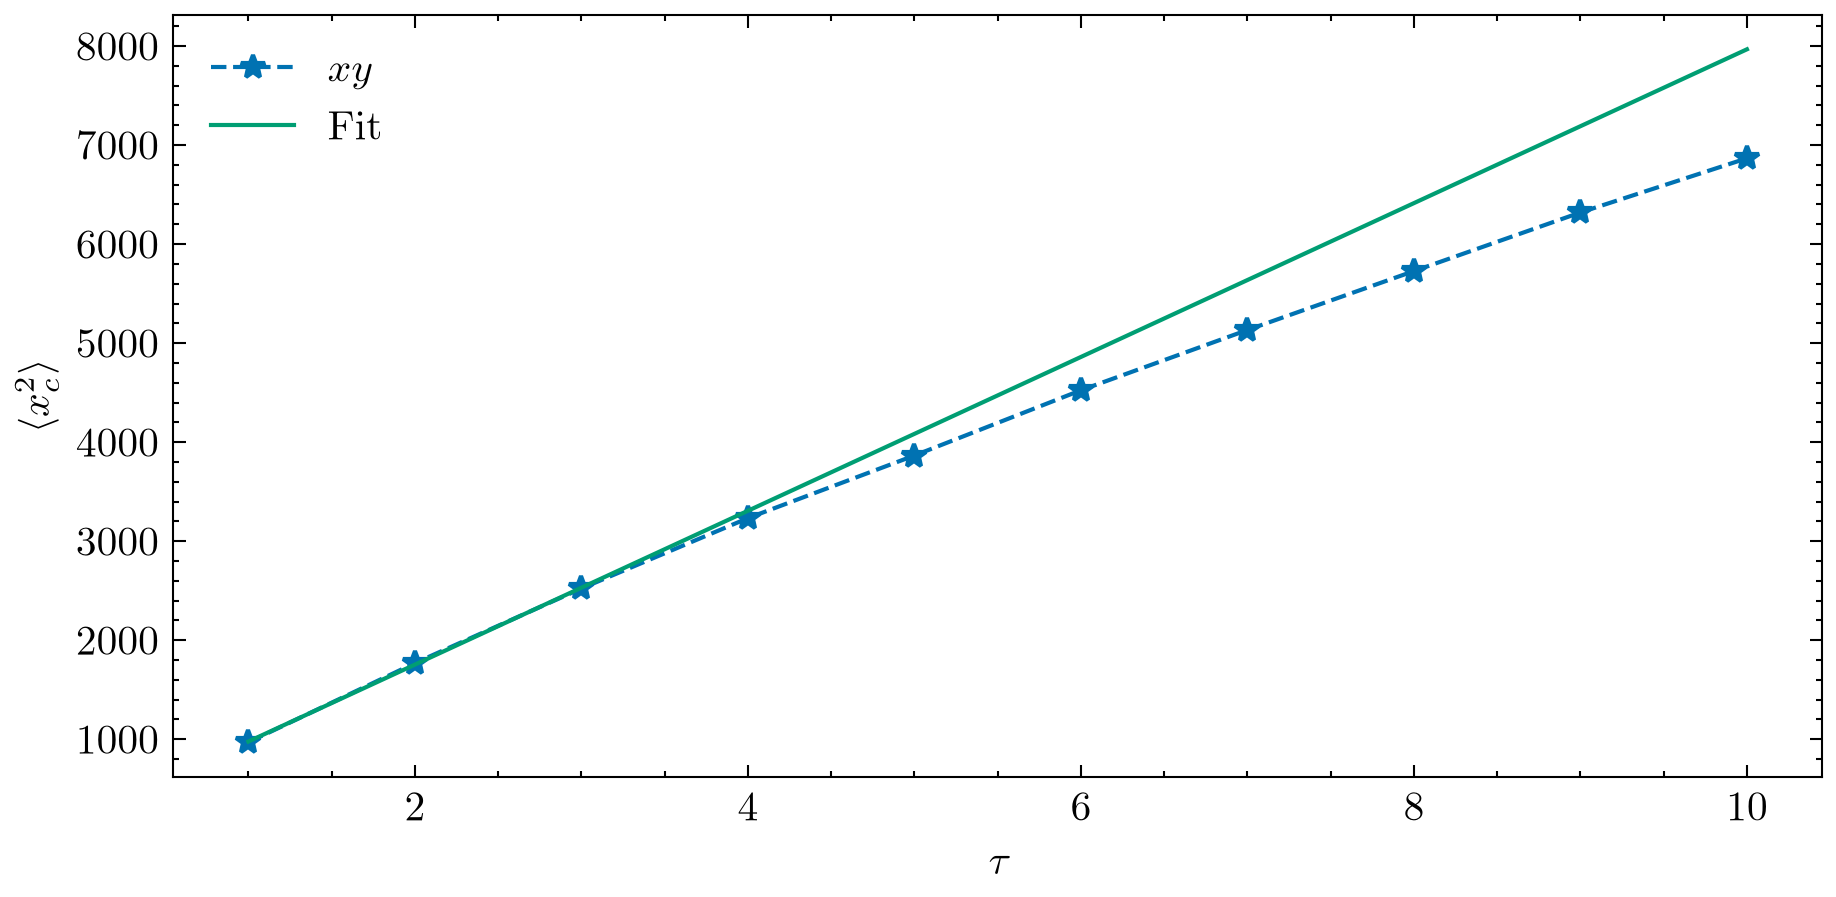

In [ ]:
def linear(x, D, b):
    return D * x + b

param, cov = curve_fit(linear, t_lag[:3], t_MSD[:3])

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t_lag[:10], t_MSD[:10], marker='*', linestyle='dashed', label=r"$xy$")
ax.plot(t_lag[:10], linear(t_lag[:10], *param), label=r"Fit")
#plt.plot(z_lag[:100], z_MSD[:100], marker='*', linestyle='dashed', label=r"$z$")
ax.legend()
ax.set_xlabel(r'$\tau$')
ax.set_ylabel(r'$\langle x^2 _c\rangle$')
save_fig(fig, "Figures/xy_MSD.svg")

WindowsPath('Figures/z_MSD.svg')

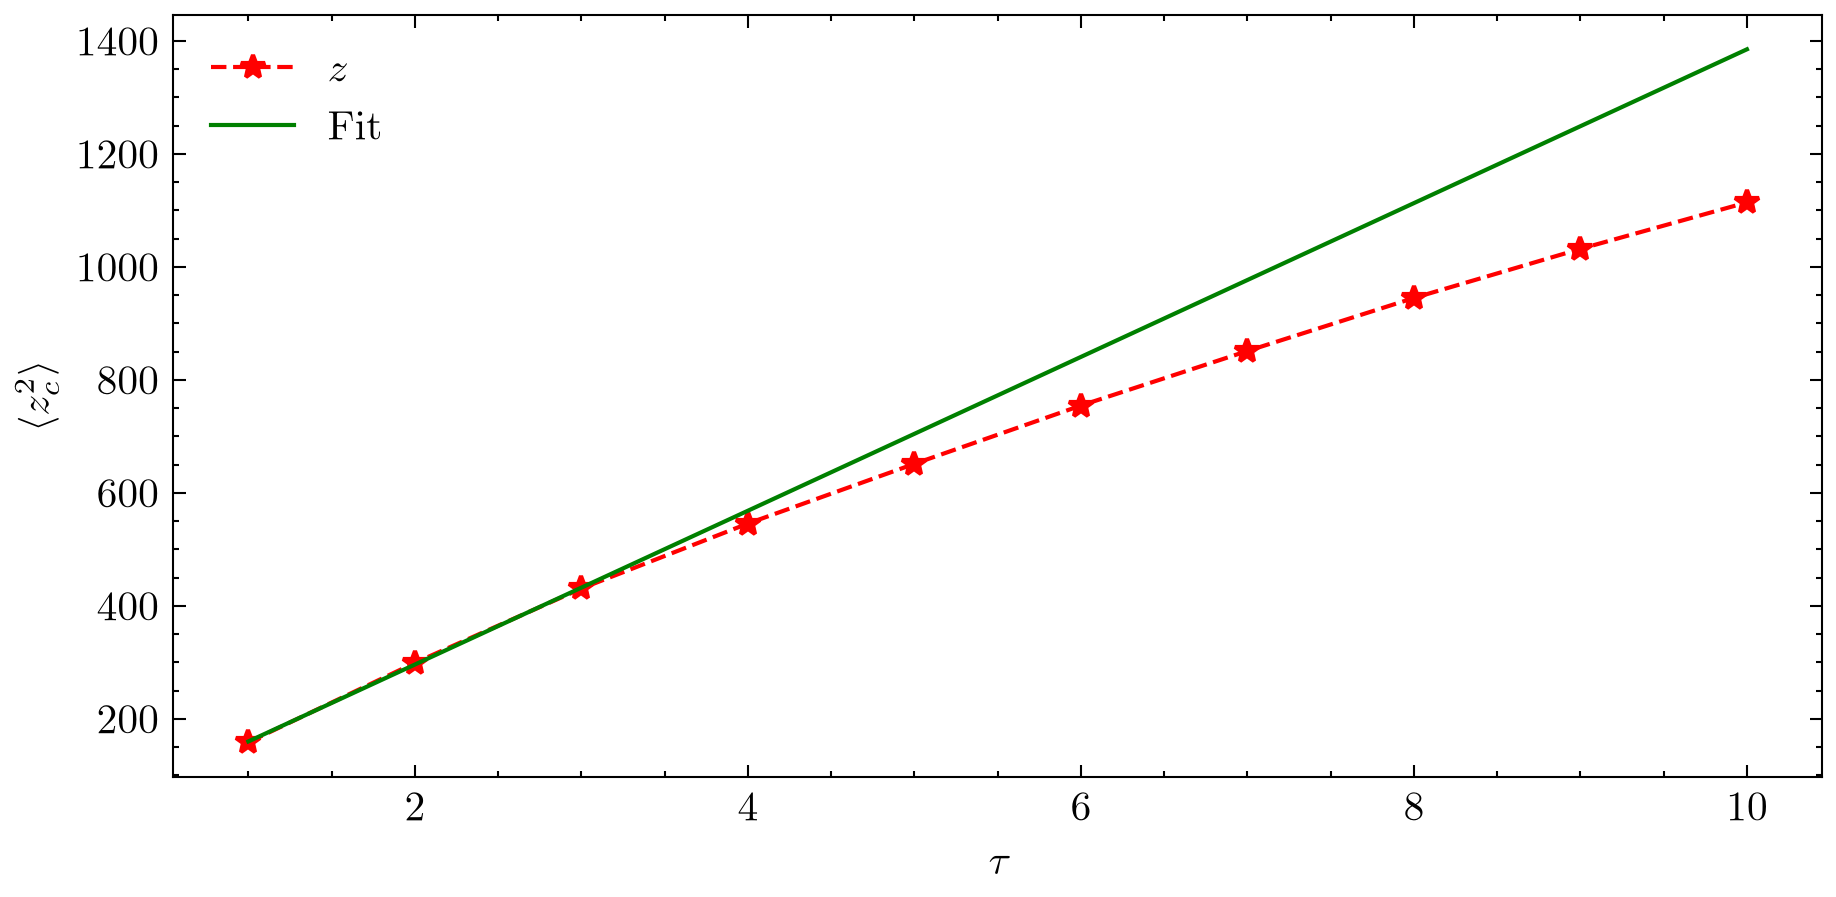

In [ ]:
def linear(x, D, b):
    return D * x + b

param, cov = curve_fit(linear, z_lag[:3], z_MSD[:3])

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(z_lag[:10], z_MSD[:10], marker='*', linestyle='dashed', label=r"$z$", color='red')
ax.plot(z_lag[:10], linear(z_lag[:10], *param), label=r"Fit", color='green')
#plt.plot(z_lag[:100], z_MSD[:100], marker='*', linestyle='dashed', label=r"$z$")
ax.legend()
ax.set_xlabel(r'$\tau$')
ax.set_ylabel(r'$\langle z^2 _c\rangle$')
save_fig(fig, "Figures/z_MSD.svg")

# iPSF Simulation Figures



In [4]:
# custom function
from hdr.axial_estimation import *              # Axial Diffusion Estimation
from hdr.transverse_estimation import *         # Transverse Diffusion Estimation
# h5 handling
from hdr.h5_tools import *
from hdr.recenter_roi import *

from scipy.io import loadmat
# load data
ipsfdata = loadmat(r'ipsfData/Particle_Zseries_focus_400.mat')

In [5]:
print(ipsfdata['save_im_array'].shape)
print(ipsfdata['z_focus'].shape)
print(ipsfdata['z_vec'].shape)

H, W, F = np.shape(ipsfdata['save_im_array'])
roi_stack = np.transpose(ipsfdata['save_im_array'], (2,0,1))

px_size = 55 #nm
wavelength = 405 #nm

from matplotlib.colors import AsinhNorm

V = np.transpose(ipsfdata['save_im_array'], (2, 0, 1)).astype(float)   # (F,H,W)=(z,y,x)
F, H, W = V.shape

dx     = 55.0                              # nm / pixel  (lateral, x & y)
z_half = ipsfdata['z_focus']                           # nm          (z runs in [-z_half, +z_half])
z      = np.linspace(0, z_half, F)   # nm          physical axial coordinate
dz     = z[1] - z[0]                        # nm / frame  (axial sampling)

zc, yc, xc = np.unravel_index(np.argmax(np.abs(V)), V.shape)   # r0 = argmax|h|
xum, yum, zum = (np.arange(W)-xc)*dx/1e3, (np.arange(H)-yc)*dx/1e3, z/1e3   # µm

signed = V.min() < -1e-9 * np.abs(V).max()      # interferometric contrast?
vmax   = np.nanpercentile(np.abs(V), 99.6)      # robust vmax (ignores hot pixels)
lw     = vmax / 30.0                             # asinh linear width I0 (wing reveal)

if signed:
    norm, cmap = AsinhNorm(linear_width=lw, vmin=-vmax, vmax=+vmax), "gray"
else:
    norm, cmap = AsinhNorm(linear_width=lw, vmin=0.0,  vmax=+vmax), "inferno"
clab = "contrast" if signed else "intensity (a.u.)"

(121, 121, 200)
(1, 1)
(1, 200)


WindowsPath('Figures/sim_ipsf.svg')

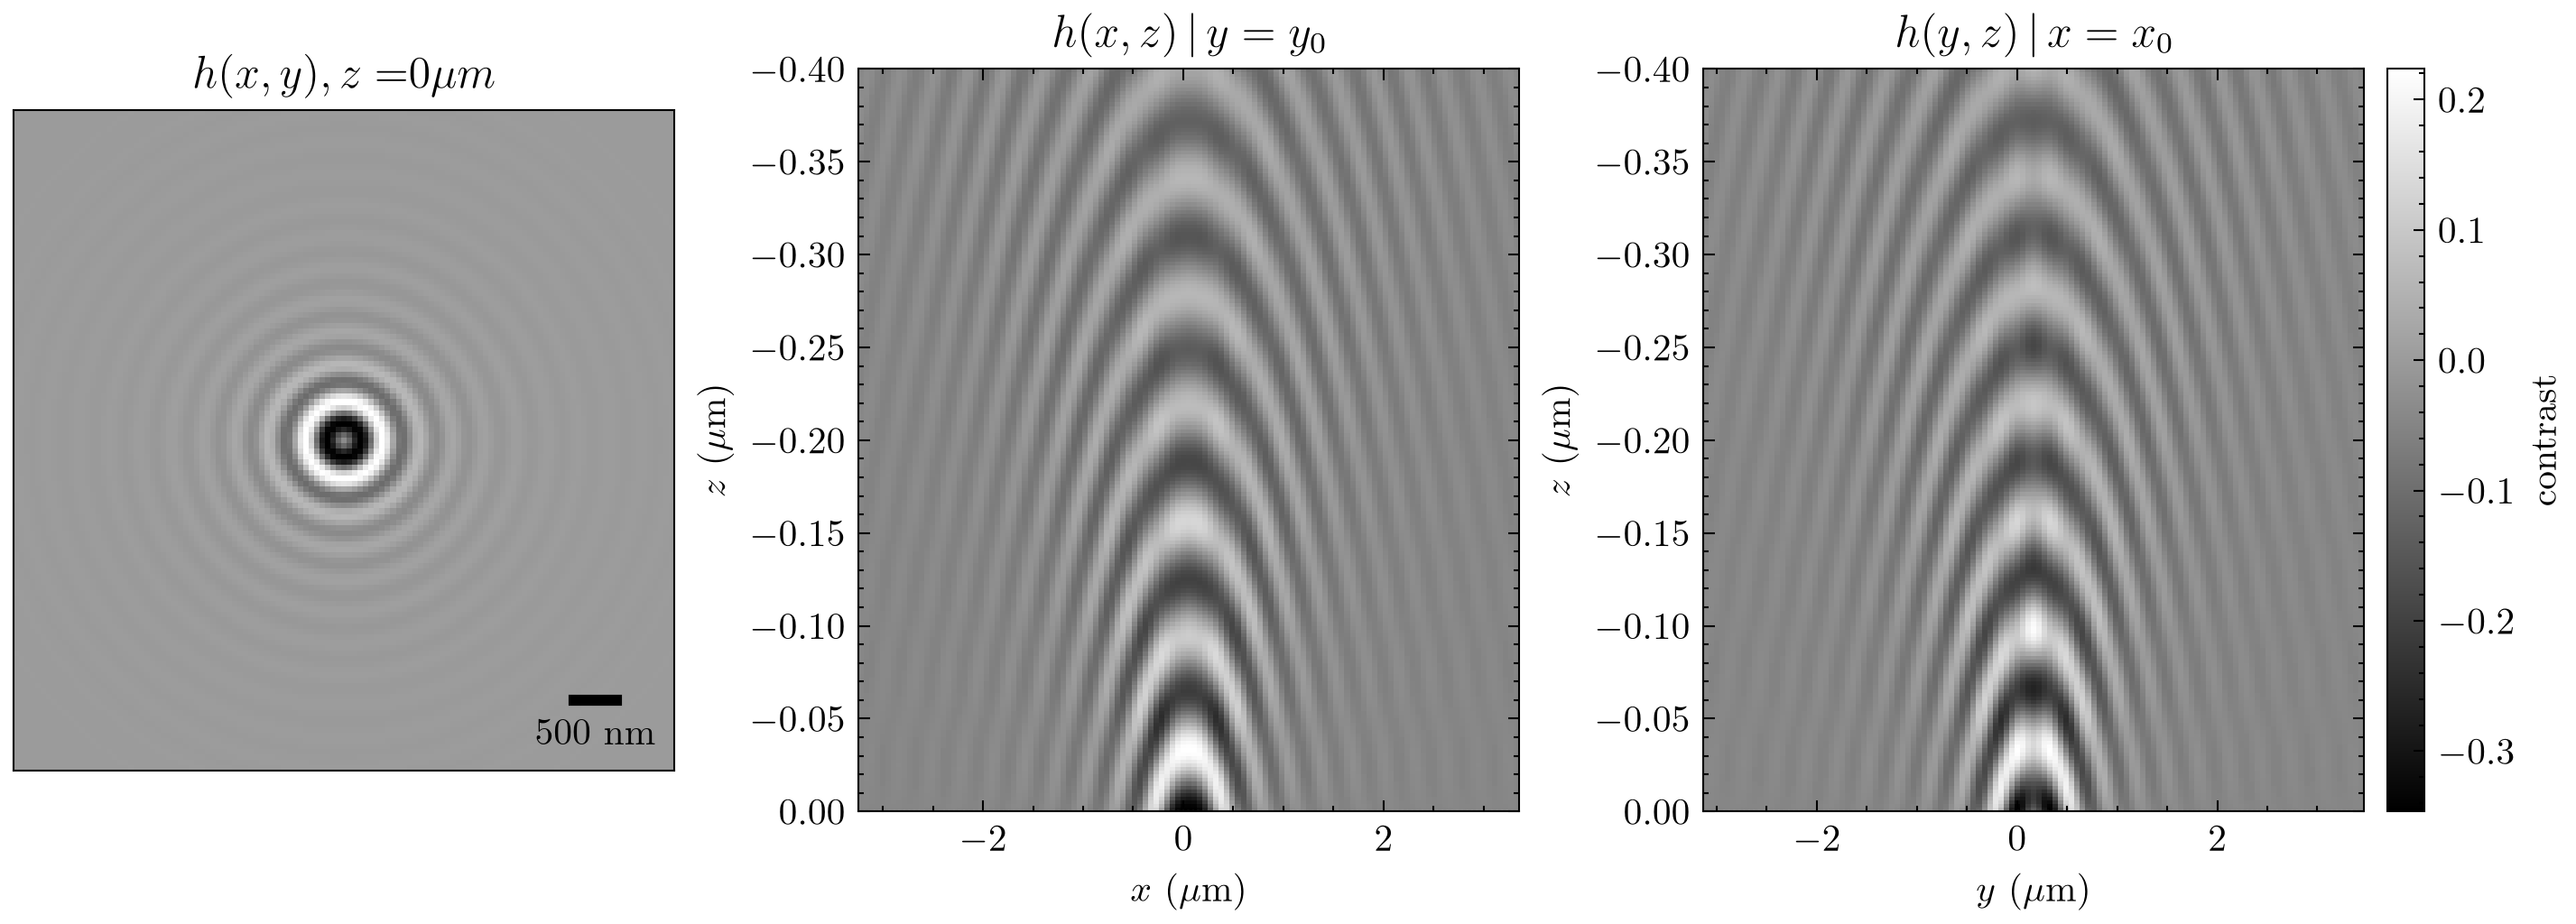

In [6]:
# %% three orthogonal sections through r0 --------------------------------
sec_xy = V[zc]         # h(x,y) | z = z0        (swap for MIP: V.max(axis=0))
sec_xz = V[:, yc, :]   # h(x,z) | y = y0        (MIP: V.max(axis=1))
sec_yz = V[:, :, xc]   # h(y,z) | x = x0        (MIP: V.max(axis=2))

fig, ax = plt.subplots(1, 3, figsize=(9.5, 3.4), constrained_layout=True)

im = ax[0].imshow(sec_xy,  cmap='gray',  interpolation="nearest", origin="lower")
ax[0].set_xticks([]); ax[0].set_yticks([])
ax[0].set_title(rf"$h(x,y), z=${zc}$\mu m$")
add_scalebar(ax[0], dx, units="nm", color="k", loc="lower right")   # en-face in px → dx exact

for a, sec, xco, xl, ttl in [(ax[1], sec_xz, xum, r"$x$", r"$h(x,z)\,|\,y=y_0$"),
                             (ax[2], sec_yz, yum, r"$y$", r"$h(y,z)\,|\,x=x_0$")]:
    a.imshow(sec,  cmap='gray', interpolation="nearest", origin="lower",
             aspect="auto", extent=[xco[0], xco[-1], zum[0], zum[-1]])   # aspect="equal" → true geometry
    a.set_title(ttl); a.set_xlabel(xl + r"$\ (\mu\mathrm{m})$"); a.set_ylabel(r"$z\ (\mu\mathrm{m})$")
    a.axhline(zum[zc], color="w", lw=0.5, ls=":")   # marks the en-face plane

cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label(clab)

save_fig(fig, r'Figures/sim_ipsf', also=['pdf', 'png'])


(200, 40)
(51,)
shapes dont match!
(200, 40)
(51,)
1.0458522436103195
 -10.00 [nm] < z < 2000.00 [nm]


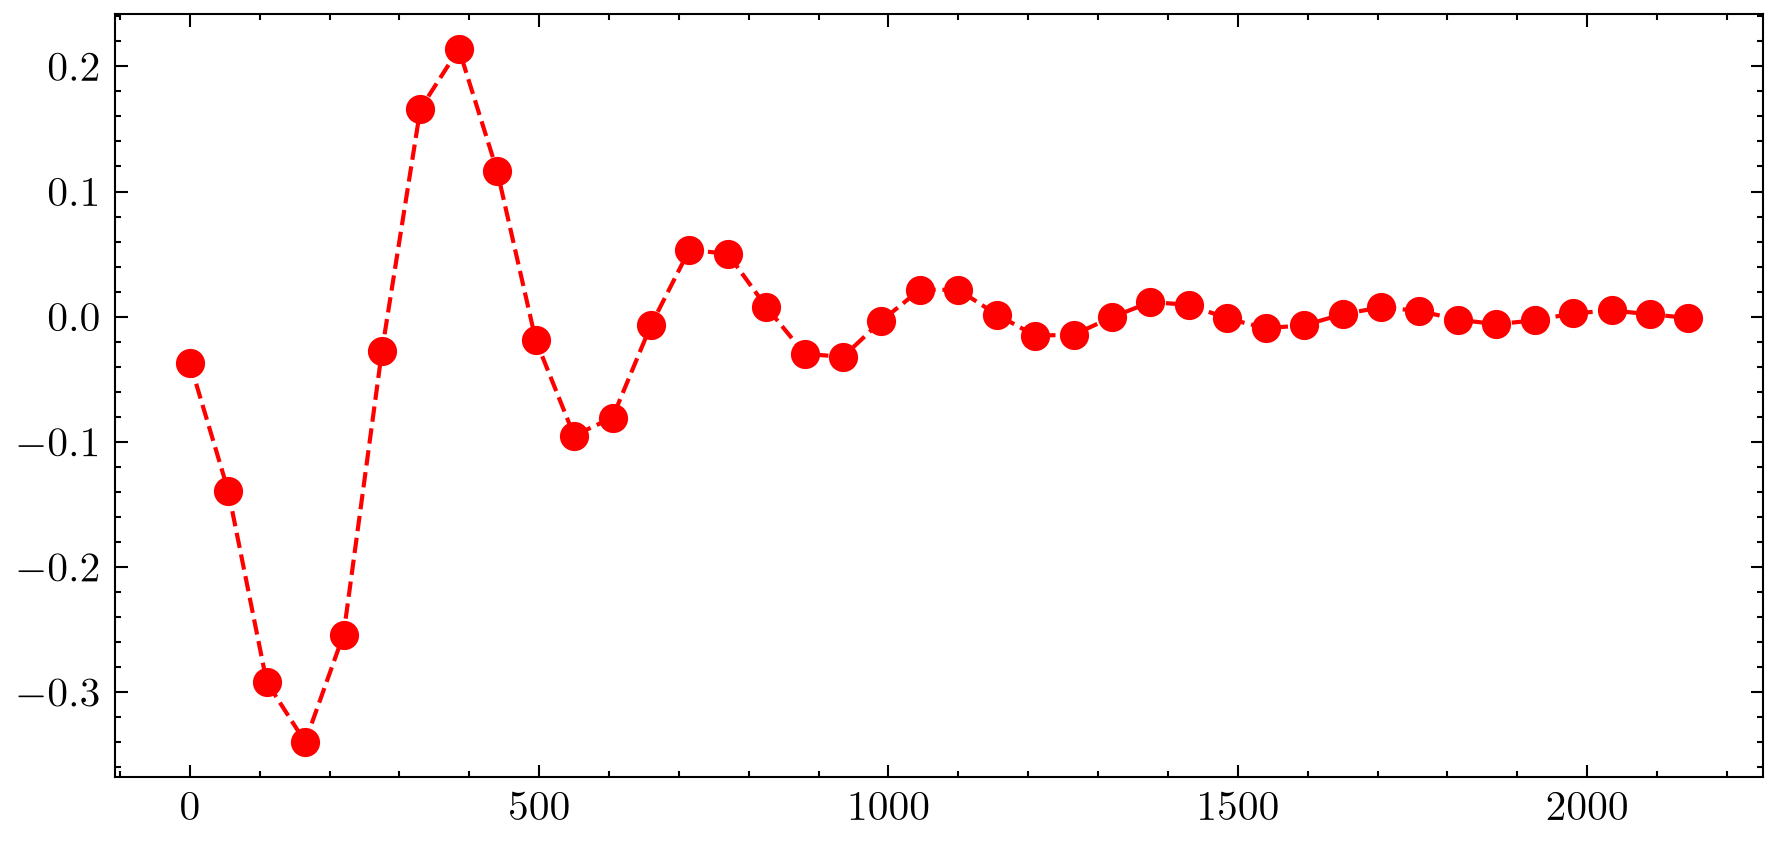

In [16]:
# do the axial estimation on this
# define weight
w_r = np.zeros((50 + 1,)) # size is int(fixed_r + 1) or (0, fixed_r) lol
#w_r[8:26] = 1
ws = 0
we = 39
w_r[ws:we] = 1
fixed_r = 39
rad_int_theta = 359
pixel_size_nm = 55
k = 2 * np.pi / (405.0 / 1.33)
# axial tracking
# opt = getAxialInference(roi                 = np.array(roi_stack),
#                         k                   = 2 * np.pi / (405.0 / 1.33),
#                         pixel_size_nm       = 55,
#                         fixed_r             = 50,
#                         rad_int_theta       = 359,
#                         theta_naught        = 0,
#                         random_angle        = False,
#                         bounds0             =[(1, 3000), (0.01, 2), (1, 5000)],
#                         z_grid_revisions    = 2,
#                         channel_length0_nm  = 10000,
#                         chain_linker_cost   = 50,   # max horizontal step in nm
#                         linker_weight       = (1.0, 0), # all weighting for steps is on dx)
#                         w_r                 = w_r,
#                         we                  = we,
#                         ws                  = ws,
#                         plot_3_param = True,
#                         plot_2_param = False,
#                         debug = True,
#                         )
# print("Axial Diffusion Success...", end='\n')

r_arr, rad_av_arr, mask_arr = get_single_radial_sample(roi_stack, 0, fixed_r=fixed_r, fixed_theta=rad_int_theta, add_disk=False, random_angle=False)

r_index_nm = np.array(r_arr) * pixel_size_nm

plt.plot(r_index_nm[0], rad_av_arr[0],'ro--')

print(r_index_nm.shape)
print(w_r.shape)
if r_index_nm.shape[1] != w_r.shape[0]:
    print('shapes dont match!')
    print(r_index_nm.shape)
    print(w_r.shape)
    w_r = np.zeros((r_index_nm.shape[1],)) # size is int(fixed_r + 1) or (0, fixed_r) lol
    w_r[ws:we] = 1

_, _, res_df = fit_nuisance_parameters(
        rad_av_arr  = rad_av_arr,
        r_index_nm  = r_index_nm,
        k           = k,
        bounds      = [(1, 10000), (0.01, 2), (1, 5000)],
        n_frames    = 200,        # increase to 50 if estimates feel unstable
        w_r         = w_r,
    )

# fit E0 to a gamma pdf
coef = gamma.fit(res_df['E0'])
mean, var, skew, kurt = gamma.stats(*coef, moments='mvsk')
E0_best = mean
# fit ef to a lognorm pdf
coef = lognorm.fit(res_df['ef'])
mean, var, skew, kurt = lognorm.stats(*coef, moments='mvsk')
ef_best = mean

z_2_param = res_df['zpp']

print(E0_best)
median_z_value = np.median(z_2_param)

# a-prioi knowledge
z_min, z_max = -10, 2000
print(f' {z_min:.2f} [nm] < z < {z_max:.2f} [nm]')

# -----------------------------------------
# STAGE 2 Grid Search in z + 2D Normalized linking
# -----------------------------------------

frames_stack = np.array(rad_av_arr, dtype=np.float64)   # (F, Nr)
r_common_nm  = np.asarray(r_index_nm[0], dtype=np.float64)




WindowsPath('Figures/nuisance_param.svg')

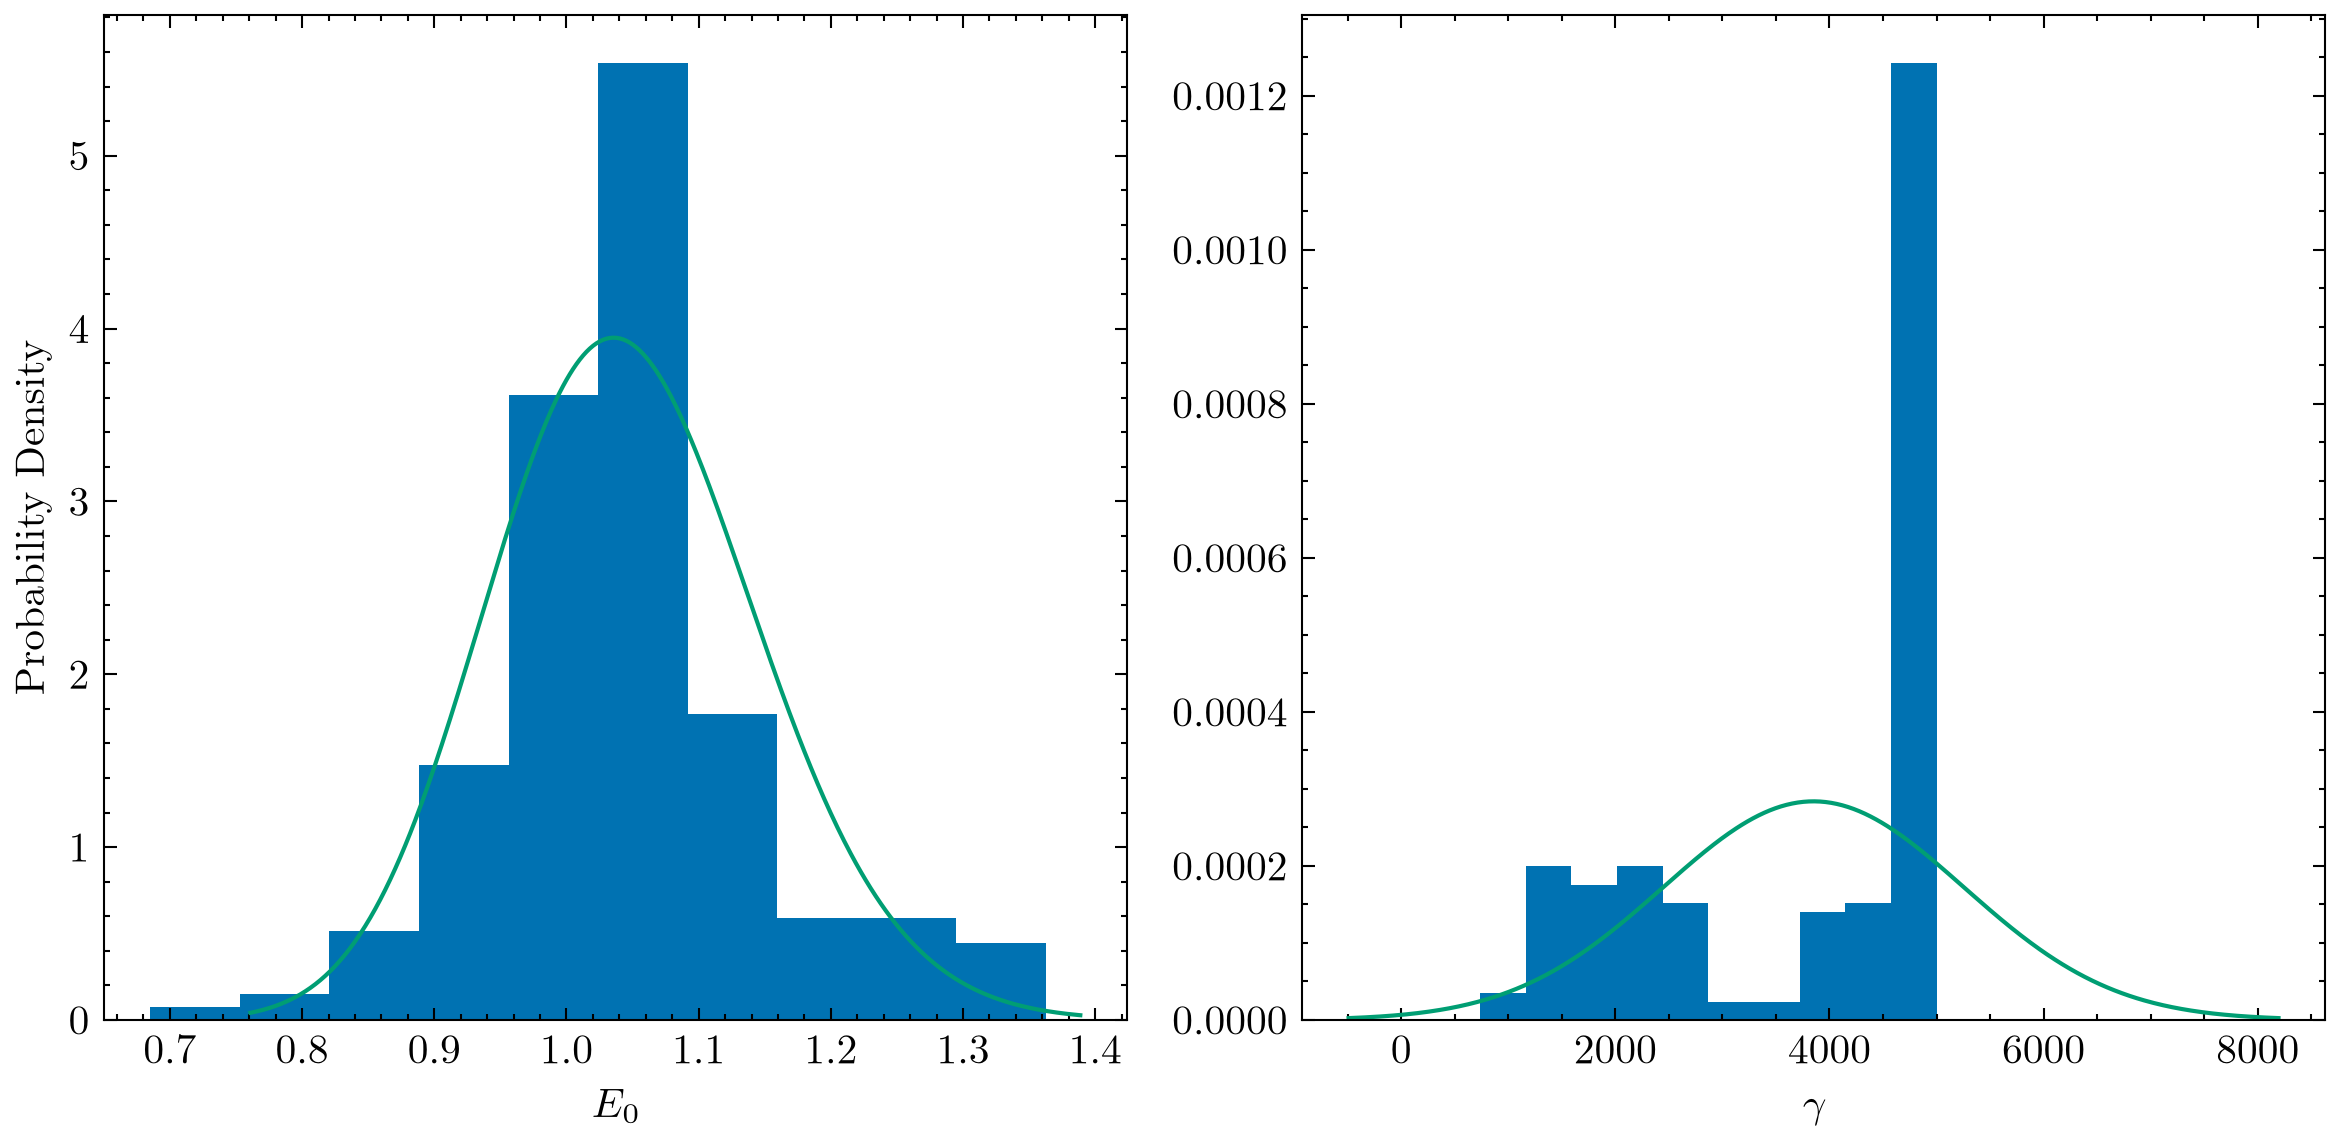

In [17]:
# fit E0 to a gamma pdf
coef = gamma.fit(res_df['E0'])
mean, var, skew, kurt = gamma.stats(*coef, moments='mvsk')

x = np.linspace(gamma.ppf(0.001, *coef), gamma.ppf(0.999, *coef), 500)
pdf1 = gamma.pdf(x, *coef)

fig = plt.figure(figsize = (8, 4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

ax1.set_ylabel('Probability Density')
ax1.set_xlabel(r'$E_0$')
ax1.hist(res_df['E0'], density=True)
ax1.plot(x,pdf1, label=r'$f(E_0)$')


# fit ef to a lognorm pdf
coef = lognorm.fit(res_df['ef'])
mean, var, skew, kurt = lognorm.stats(*coef, moments='mvsk')
x = np.linspace(lognorm.ppf(0.001, *coef), lognorm.ppf(0.999, *coef), 500)

pdf2 = lognorm.pdf(x, *coef)
ax2.set_xlabel(r'$\gamma$')
ax2.hist(res_df['ef'], density=True)
ax2.plot(x,pdf2, label=r'$f(\gamma)$')

plt.tight_layout()
save_fig(fig, 'Figures/nuisance_param', also=['pdf', 'png'])

In [18]:
w_r = np.zeros((len(r_common_nm),)) # size is int(fixed_r + 1) or (0, fixed_r) lol
print(len(r_common_nm))
#w_r[8:26] = 1
ws = 0
we = 39
w_r[ws:we] = 1
#w_r = None
try:
    grid_guess, z_guess = grid_search_z(
    frames_arr = frames_stack,
    r_nm       = r_common_nm,
    k          = k,
    E0         = E0_best,
    ef         = ef_best,
    z_lo       = z_min,
    z_hi       = z_max,
    n_z        = 10000,
    w_r        = w_r,
    )

except Exception as e:
    print(e)
    print('----------- failed on z_grid_search -----------')

# Return Grid Search and Link
sec_grad_z            = np.diff(grid_guess, n=1, axis=1)
local_minima          = (sec_grad_z[:, :-1] < 0) & (sec_grad_z[:, 1:] > 0)
min_idx  = [np.where(local_minima[f])[0] + 1 for f in range(local_minima.shape[0])]
min_vals = [grid_guess[f, idx] for f, idx in enumerate(min_idx)]

best_idx_chain, best_coord_chain, best_cost_chain = best_chain_2d(
                min_idx, min_vals, max_step=6, w=(1,1)
            )

z_minima = z_guess[best_coord_chain] 
z_vec = ipsfdata['z_vec'][0]

z_disp_1param = np.diff(z_minima)
z_disp_3param = np.diff(z_2_param)
z_disp_true = np.diff(z_vec)

# if w_r == None:
#     plt.title(f'w_r = {w_r}')


40


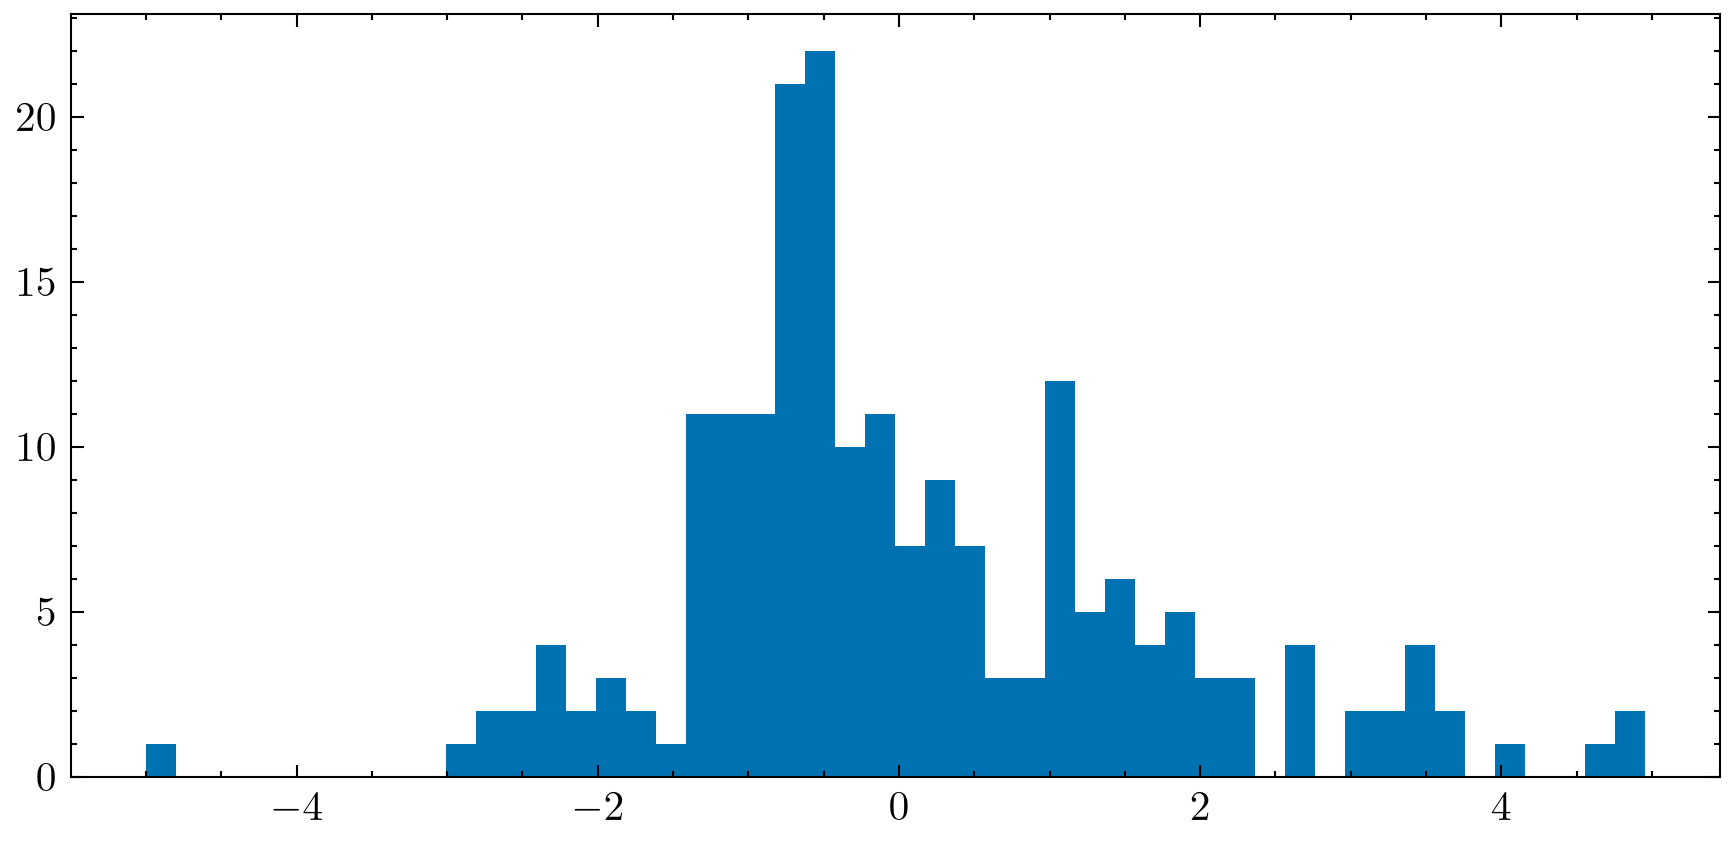

In [ ]:
plt.hist((z_minima - z_minima[0] - z_vec), bins=50)
plt.show()

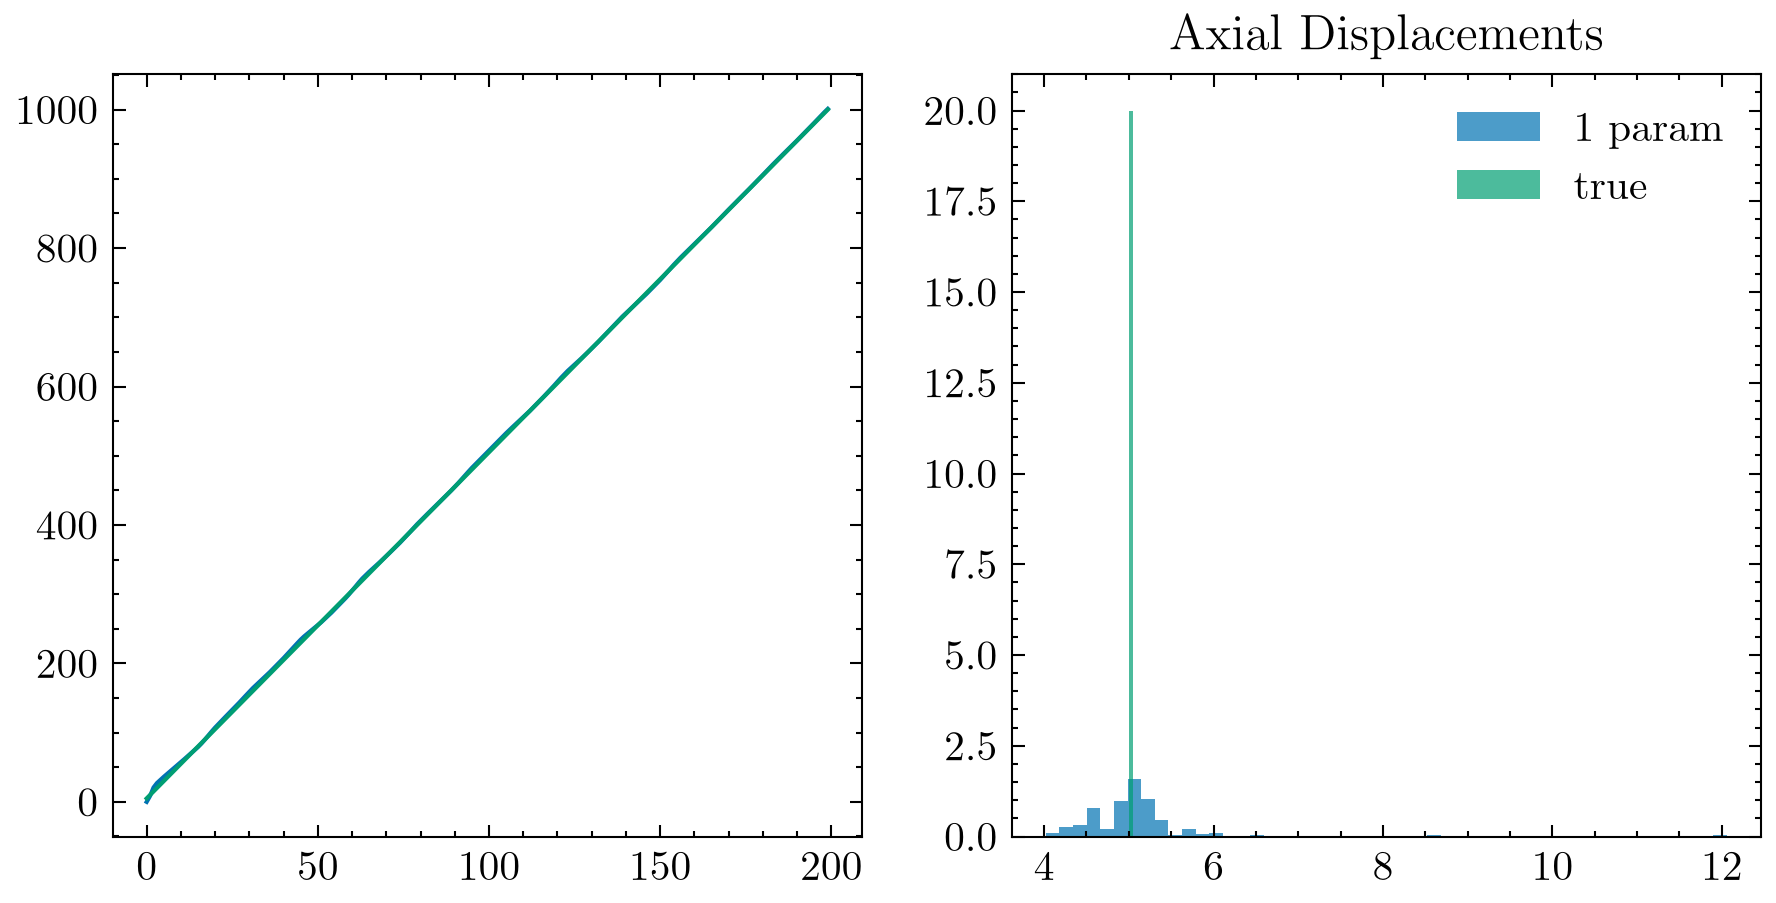

In [ ]:
fig, (ax1, ax2) = plt.subplots(1,2)
#ax1.plot(z_2_param - z_2_param[0])
ax1.plot(z_minima - z_minima[0])
ax1.plot(ipsfdata['z_vec'][0,:] )
#ax2 = fig.add_subplot(122)
ax2.hist(z_disp_1param, density=True, bins=50, alpha=0.7, label='1 param')
#ax2.hist(z_disp_3param, density=True, bins=20, alpha=0.7, label='3 param')
ax2.hist(z_disp_true,   density=True, bins=20, alpha=0.7, label='true')
ax2.legend()
ax2.set_title('Axial Displacements')
#ax2.plot(z_minima - z_vec[0] -  np.min(z_minima))
#ax2.set_title('Residuals')
plt.show()




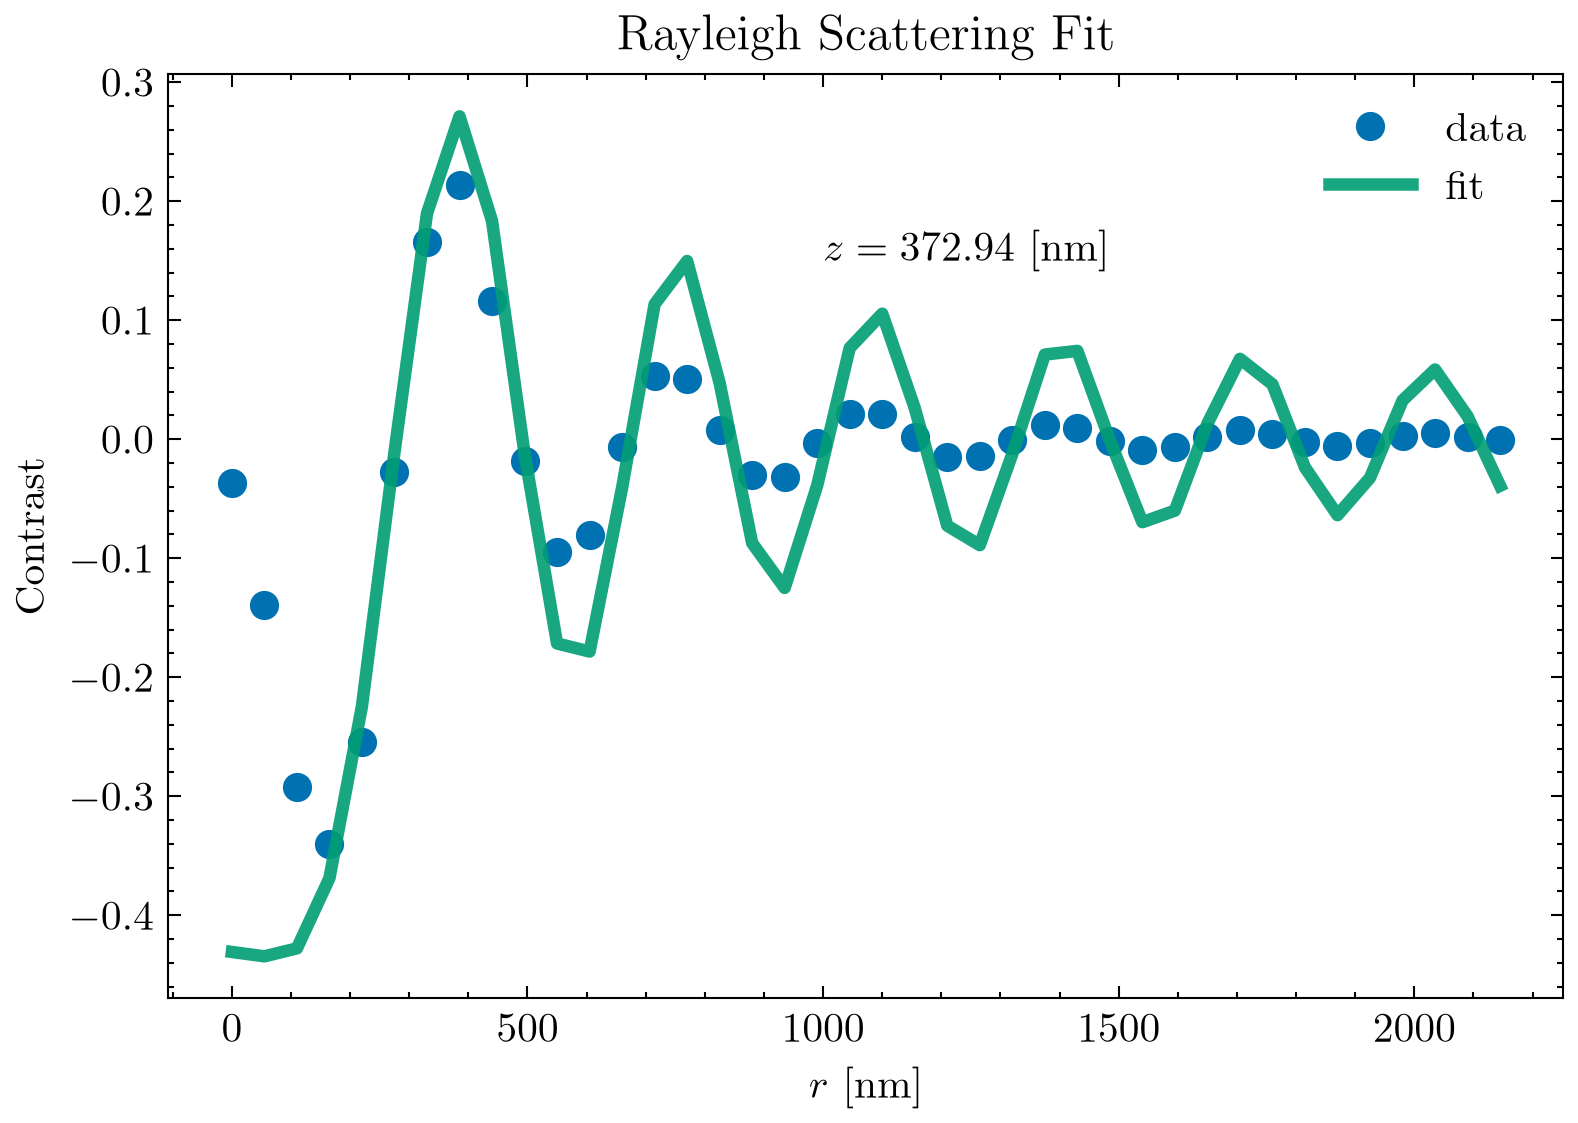

In [ ]:
# z_traj = opt['z']
# r_arr = opt['r_arr']
# rad_av_arr = opt['rad_av_arr']
# roi_dss = opt['roi']
# marr = opt['mask_arr']

# plt.plot(z_traj - z_traj[0])
# plt.plot(ipsfdata['z_vec'][0,:])

fit = iPSF_radial(r_index_nm, 2 * np.pi / (405.0 / 1.33) , z_2_param[0], E0_best, 0, ef_best) 

# plt.imshow(roi_dss[0])
# plt.imshow(marr[0], alpha=0.5)
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(r_index_nm[0], rad_av_arr[0], label='data', marker='o', linestyle ='None')
ax.plot(r_index_nm[0], fit[0], label='fit', linewidth=3, alpha=0.9)
ax.legend()
ax.set_ylabel('Contrast')
ax.set_xlabel(r'$r$ [nm]')
ax.set_title('Rayleigh Scattering Fit')

ax.text(1000, 0.15, f'$z = {z_traj[0]:.2f}$ [nm]')
#save_fig(fig, r'Figures/Rayleigh Fit.svg')
plt.show()

# Good iPSF figures

Sampling: 0.0


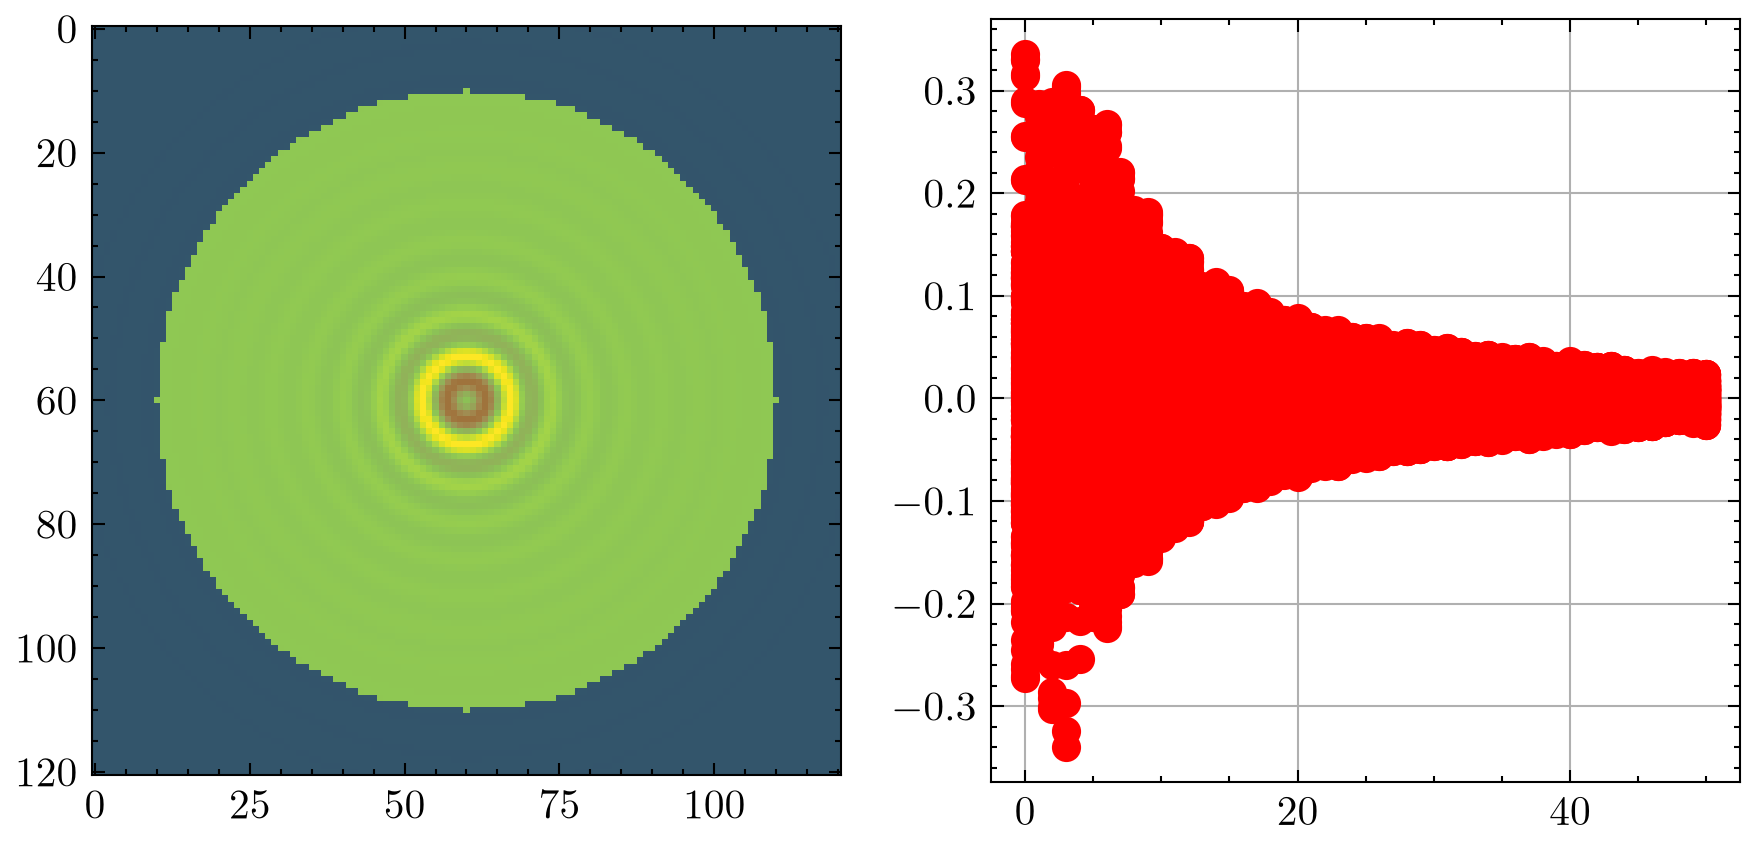

(200, 51)
(51,)
nuisance param: 0.27
 -1010.50 [nm] < z < 1989.50 [nm]
Axial Diffusion Success...


In [8]:
# define weight
w_r = np.zeros((50 + 1,)) # size is int(fixed_r + 1) or (0, fixed_r) lol
#w_r[8:26] = 1
ws = 0
we = 39
w_r[ws:we] = 1
fixed_r = 39
rad_int_theta = 359
pixel_size_nm = 55
k = 2 * np.pi / (405.0 / 1.33)
# axial tracking
opt = getAxialInference(roi                 = np.array(roi_stack),
                        k                   = 2 * np.pi / (405.0 / 1.33),
                        pixel_size_nm       = 55,
                        fixed_r             = 50,
                        rad_int_theta       = 359,
                        theta_naught        = 0,
                        random_angle        = False,
                        bounds0             =[(1, 3000), (0.01, 2), (1, 5000)],
                        z_grid_revisions    = 2,
                        channel_length0_nm  = 3000,
                        chain_linker_cost   = 5,   # max horizontal step in nm
                        linker_weight       = (1.0, 1.0), # all weighting for steps is on dx)
                        w_r                 = w_r,
                        we                  = we,
                        ws                  = ws,
                        plot_3_param = True,
                        plot_2_param = False,
                        debug = True,
                        )
print("Axial Diffusion Success...", end='\n')

z_gs = opt['z']
sel = opt['sel']

In [26]:
err = np.sum(sel, axis=1)

WindowsPath('Figures/simulation_fit_residual.svg')

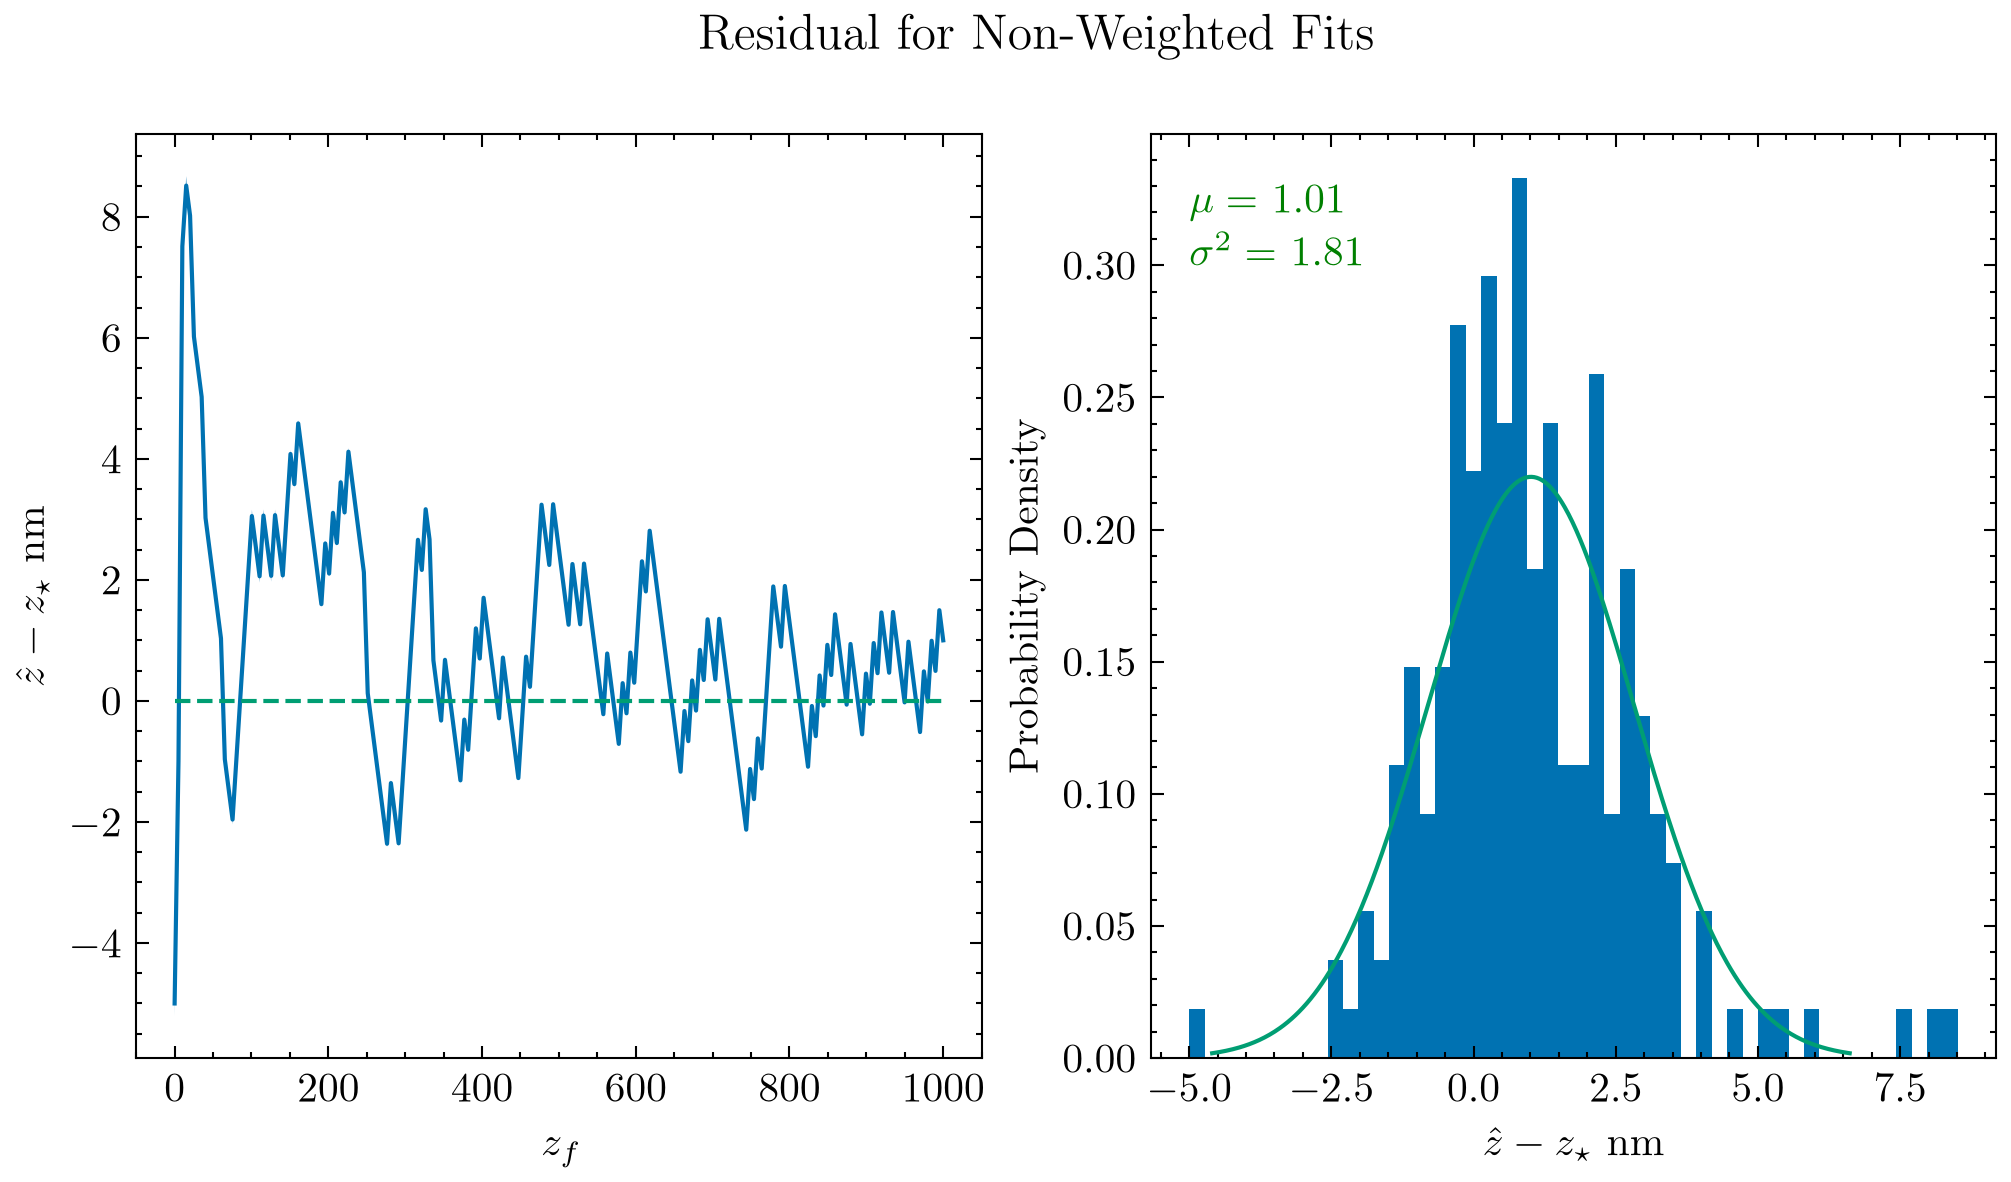

In [41]:
from scipy.stats import norm

trans = z_gs - z_gs[0] - z_vec

coef = norm.fit(trans)
x = np.linspace(norm.ppf(0.001, *coef), norm.ppf(0.999, *coef), 500)
pdf = norm.pdf(x, *coef)

fig = plt.figure(figsize=(8, 4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

ax2.hist((z_gs - z_gs[0] - z_vec), bins=50, density=True)
ax2.plot(x, pdf)
ax2.text(-5, 0.32, rf'$\mu =$ {coef[0]:.2f}'  , color='green')
ax2.text(-5, 0.3, rf'$\sigma^2 =$ {coef[1]:.2f}', color='green')
ax2.set_xlabel(r'$\hat{z} - z_\star$ nm')
ax2.set_ylabel('Probability Density')
fig.suptitle('Residual for Non-Weighted Fits')

x = np.linspace(0, 1000, 200)
ax1.plot(x, trans)
ax1.plot(x, 0 * x, r'--', markersize=1)
ax1.fill_between(x,  err + trans, -err+ trans, alpha=0.5)
ax1.set_xlabel('$z_f$')
ax1.set_ylabel(r'$\hat{z} - z_\star$ nm')
save_fig(fig, 'Figures/simulation_fit_residual', also=['pdf', 'png'])